# Data analysis: from raw EDF to training windows

Walks the data pipeline step by step, from the raw EDF recordings to the 10 s training windows and their BPM labels. No model analysis here (see `results.ipynb`).

Pipeline (`src/bpm/`): `edf_io.read_channels` → ECG R-peaks (`ground_truth`) → 1 Hz HR curve → quality gates (NaN seconds) → PPG bandpass (`preprocessing`) → 10 s windows, 2 s stride (`windowing.make_windows`) → optional time-warp bootstrap (`timewarp`).

Prerequisite: `scripts/build_manifest.py`, `scripts/build_cache.py` and (for the bootstrap bars) `scripts/build_bootstrap.py` have been run. Only the two used sub-datasets are covered (`wrist-ppg-during-exercise` is excluded, see `README.md`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import neurokit2 as nk
import numpy as np
import pandas as pd
from scipy.signal import welch
from scipy.stats import kurtosis

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from bpm import ground_truth as gt
from bpm.cache import WINDOW_S, STRIDE_S, read_ppg_and_hr
from bpm.data_loading import subjects_by_dataset_from_manifest
from bpm.dataset import zscore_window
from bpm.edf_io import read_channels
from bpm.manifest import MULTISITE_DIR, WRISTFINGER_DIR
from bpm.preprocessing import bandpass_filter
from bpm.split import subject_wise_split
from bpm.timewarp import ppg_hr_agrees, source_label, warp_window
from bpm.windowing import make_windows
from build_bootstrap import H_BINS, L_BINS, TARGET_PER_BIN

DATA_ROOT = ROOT / "harmonized_ecg_ppg_databases"
MANIFEST_PATH = ROOT / "cache" / "manifest.csv"
CACHE_DIR = ROOT / "cache" / "windows"
BOOTSTRAP_DIR = ROOT / "cache" / "bootstrap"
DATASETS = [WRISTFINGER_DIR, MULTISITE_DIR]

## Style

Single source of truth for every plot below: change a value here and re-run the notebook. Colors come from a colorblind-safe categorical palette and are bound to **roles**, so a role keeps its color in every figure (ECG is always blue, PPG always orange, rejected seconds always red). At most three colored series share a panel; more categories are split into panels.

In [2]:
COLORS = {
    # signals
    "ecg": "#2a78d6", "ppg": "#eb6834", "ppg_filtered": "#1baf7a",
    "rpeak": "#0b0b0b",       # Pan-Tompkins R-peaks (label detector)
    "rpeak_nk": "#c98500",    # neurokit R-peaks (second detector for bSQI)
    "hr": "#0b0b0b",
    # quality
    "rejected": "#e34948", "kept": "#1baf7a", "window": "#52514e",
    # label sources
    "real": "#2a78d6", "boot": "#eb6834",
    # splits
    "train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a",
    # ink and surface
    "text": "#0b0b0b", "muted": "#52514e", "grid": "#d9d8d4", "surface": "#ffffff",
}
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STYLE = {
    "fig_w": 12, "row_h": 2.6, "dpi": 110,
    "font": 10, "title": 12,
    "lw": 1.3, "lw_thin": 0.9, "alpha_shade": 0.18, "alpha_window": 0.10, "marker": 30,
}

plt.rcParams.update({
    "figure.dpi": STYLE["dpi"], "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "figure.constrained_layout.use": True,
    "font.size": STYLE["font"], "axes.titlesize": STYLE["title"], "axes.labelsize": STYLE["font"],
    "figure.titlesize": STYLE["title"] + 1, "legend.fontsize": STYLE["font"] - 1, "legend.frameon": False,
    "text.color": COLORS["text"], "axes.labelcolor": COLORS["text"], "axes.edgecolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": STYLE["lw"], "axes.prop_cycle": plt.cycler(color=PALETTE),
})


def figsize(rows, w=None):
    return (w or STYLE["fig_w"], STYLE["row_h"] * rows)


def runs(mask):
    """(start, end) index pairs of the True runs in a bool array."""
    d = np.diff(np.r_[0, np.asarray(mask, int), 0])
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))


def shade_seconds(ax, mask, t0=0, label="rejected (NaN)"):
    """Red span over every True second of a 1 Hz mask; t0 = time of mask[0]."""
    for i, (a, b) in enumerate(runs(mask)):
        ax.axvspan(t0 + a, t0 + b, color=COLORS["rejected"], alpha=STYLE["alpha_shade"], lw=0,
                   label=label if i == 0 else None)


def mark_window(axes, start_s, window_s=WINDOW_S):
    for ax in np.atleast_1d(axes):
        ax.axvspan(start_s, start_s + window_s, color=COLORS["window"], alpha=STYLE["alpha_window"], lw=0)
        for x in (start_s, start_s + window_s):
            ax.axvline(x, color=COLORS["window"], lw=STYLE["lw_thin"], ls="--")

## Helpers: per-gate quality masks

The library merges the gates: `ecg_quality_mask` = flat ECG + bSQI, `ecg_to_hr_curve` = HR range + RR ratio, `read_ppg_and_hr` adds flat PPG. To show which gate fired, `gate_masks` re-runs the same steps with the library's constants and keeps one 1 Hz mask per gate. The assert below checks that the union of the gates equals the NaN seconds of `read_ppg_and_hr`.

| gate | rule |
|---|---|
| flat ECG | 1 s peak-to-peak of the cleaned ECG ≤ 10% of the recording median |
| bSQI < 0.8 | Pan-Tompkins and neurokit R-peaks agree on < 80% of beats in a 10 s block (±0.15 s tolerance) |
| HR outside 30-220 | instantaneous HR of a beat outside 30-220 BPM |
| RR ratio > 1.2 | an RR interval changes by more than 1.2× versus the previous one |
| flat PPG | raw PPG constant over 1 s (sensor off / padding) |
| outside beats | before the 2nd or after the last R-peak (no HR defined) |

In [3]:
GATES = ["flat ECG", "bSQI < 0.8", "HR outside 30-220", "RR ratio > 1.2", "flat PPG"]


def beat_span_mask(peak_t, bad, n):
    """Seconds inside [peak_i, peak_i+1] of every bad beat (same rule as ecg_to_hr_curve)."""
    m = np.zeros(n, bool)
    for a, b in zip(peak_t[:-1][bad], peak_t[1:][bad]):
        m[int(np.ceil(a)) : int(np.floor(b)) + 1] = True
    return m


def gate_masks(ecg, ppg, fs):
    n, sec = int(len(ecg) // fs), int(fs)
    cleaned = nk.ecg_clean(ecg, sampling_rate=fs)
    ptp = np.ptp(cleaned[: n * sec].reshape(n, sec), axis=1)
    flat_ecg = ptp <= gt._FLAT_FRAC * np.median(ptp)

    p1 = gt._neurokit2_r_peak_detector(ecg, fs)
    _, info = nk.ecg_peaks(cleaned, sampling_rate=fs, method="neurokit")
    p2 = np.asarray(info["ECG_R_Peaks"])
    t1, t2 = p1 / fs, p2 / fs
    bsqi = np.zeros(n, bool)
    for a in range(0, n, gt._BSQI_WIN_S):
        b = a + gt._BSQI_WIN_S
        x, y = t1[(t1 >= a) & (t1 < b)], t2[(t2 >= a) & (t2 < b)]
        if len(x) < 2 or len(y) < 2:
            bsqi[a:b] = True
            continue
        j = np.clip(np.searchsorted(y, x), 1, len(y) - 1)
        matched = np.sum(np.minimum(np.abs(y[j] - x), np.abs(y[j - 1] - x)) <= gt._BSQI_TOL_S)
        bsqi[a:b] = matched / (len(x) + len(y) - matched) < gt._BSQI_MIN

    rr = np.diff(t1)
    inst_hr = 60 / rr
    hr_range = (inst_hr < gt._HR_MIN) | (inst_hr > gt._HR_MAX)
    rr_ratio = np.zeros(len(rr), bool)
    rr_ratio[1:] = (rr[1:] / rr[:-1] > gt._RR_RATIO_LIMIT) | (rr[1:] / rr[:-1] < 1 / gt._RR_RATIO_LIMIT)

    t = np.arange(n, dtype=float)
    outside = np.ones(n, bool) if len(t1) < 2 else (t < t1[1]) | (t > t1[-1])
    raw_curve = np.full(n, np.nan)
    if len(t1) >= 2:
        raw_curve[~outside] = np.interp(t[~outside], t1[1:], inst_hr)

    masks = {
        "flat ECG": flat_ecg,
        "bSQI < 0.8": bsqi,
        "HR outside 30-220": beat_span_mask(t1, hr_range, n),
        "RR ratio > 1.2": beat_span_mask(t1, rr_ratio, n),
        "flat PPG": np.ptp(ppg[: n * sec].reshape(n, sec), axis=1) == 0,
    }
    rejected = outside | np.any(list(masks.values()), axis=0)
    return {"masks": masks, "outside": outside, "rejected": rejected, "raw_curve": raw_curve,
            "curve": np.where(rejected, np.nan, raw_curve), "p1": p1, "p2": p2, "cleaned": cleaned,
            "inst_hr": inst_hr, "n": n}


def load_file(rel_path):
    signals, fs = read_channels(DATA_ROOT / rel_path, ["ECG", "PPG"])
    g = gate_masks(signals["ECG"], signals["PPG"], fs)
    g.update(ecg=signals["ECG"], ppg=signals["PPG"], ppg_bp=bandpass_filter(signals["PPG"], fs), fs=fs,
             path=rel_path)
    return g


def ppg_rate(window, fs):
    """PPG spectral-peak BPM of one window (same method as timewarp.ppg_hr_agrees)."""
    w = len(window)
    freqs = np.fft.rfftfreq(4 * w, 1 / fs)
    power = np.abs(np.fft.rfft((window - window.mean()) * np.hanning(w), 4 * w))
    band = (freqs >= 0.6) & (freqs <= 3.5)
    return 60 * freqs[band][power[band].argmax()], freqs * 60, power

In [4]:
manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest[manifest.sub_dataset.isin(DATASETS)]

# shortcut: 2 multisite files per subject (1800-20000 s), not all 519; run all files if exact gate rates matter
ms_sample = (manifest[(manifest.sub_dataset == MULTISITE_DIR) & manifest.duration_sec.between(1800, 20000)]
             .sort_values("duration_sec").groupby("global_subject_id").head(2))
scan_rows = pd.concat([manifest[manifest.sub_dataset == WRISTFINGER_DIR], ms_sample])

SCAN = {}
for row in scan_rows.itertuples():
    signals, fs = read_channels(DATA_ROOT / row.file_path, ["ECG", "PPG"])
    g = gate_masks(signals["ECG"], signals["PPG"], fs)
    SCAN[row.file_path] = {"sub_dataset": row.sub_dataset, "subject": row.global_subject_id,
                           "masks": g["masks"], "outside": g["outside"], "rejected": g["rejected"], "n": g["n"]}

# the per-gate split must reproduce the library's NaN seconds exactly
for rel in [scan_rows.file_path.iloc[0], ms_sample.file_path.iloc[0]]:
    _, lib_curve, _ = read_ppg_and_hr(DATA_ROOT / rel)
    assert np.array_equal(np.isnan(lib_curve), SCAN[rel]["rejected"]), rel
print(f"scanned {len(SCAN)} files: {(scan_rows.sub_dataset == WRISTFINGER_DIR).sum()} wrist-finger, "
      f"{len(ms_sample)} multisite ({ms_sample.duration_sec.sum() / 3600:.1f} h)")

scanned 199 files: 165 wrist-finger, 34 multisite (75.3 h)


## Data summary

One table to get a feel for size and quality of the data, per sub-dataset and pooled. Sources:
- **recordings**: `cache/manifest.csv`, all files.
- **quality**: the gate scan above (all wrist-finger files, multisite sample only, so multisite rates are estimates).
- **windows / labels / split / bootstrap**: the window caches (`cache/windows/`, `cache/bootstrap/`), all subjects.

"Candidate windows" = every 10 s / 2 s-stride window the raw files allow. "Cached windows" = what survives the gates and the multisite cap (2000 per subject).

In [5]:
rows = []
for rel, s in SCAN.items():
    r = {"sub_dataset": s["sub_dataset"], "seconds": s["n"], "outside beats": s["outside"].sum(),
         "any gate": s["rejected"].sum()}
    r.update({gname: m.sum() for gname, m in s["masks"].items()})
    st = np.arange(0, s["n"] - WINDOW_S + 1, STRIDE_S)
    r["windows"] = len(st)
    r["windows kept"] = sum(not s["rejected"][k : k + WINDOW_S].any() for k in st)
    rows.append(r)
gate_df = pd.DataFrame(rows).groupby("sub_dataset").sum()
cols = GATES + ["outside beats", "any gate"]
share = 100 * gate_df[cols].div(gate_df.seconds, axis=0)
share["windows kept"] = 100 * gate_df["windows kept"] / gate_df.windows
split = subject_wise_split(subjects_by_dataset_from_manifest(MANIFEST_PATH), seed=42)
split_of = {sid: name for name, ids in split.items() for sid in ids}


def labels_from(directory):
    out = []
    for f in sorted(Path(directory).glob("*.npz")):
        d = np.load(f)
        out.append(pd.DataFrame({"subject": f.stem, "sub_dataset": d["dataset_source"], "bpm": d["labels"]}))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=["subject", "sub_dataset", "bpm"])


real = labels_from(CACHE_DIR)
real["split"] = real.subject.map(split_of)
boot = {letter: labels_from(BOOTSTRAP_DIR / letter) for letter in "LH"}

from bpm.cache import MULTISITE_CAP_PER_SUBJECT


def dur(sec):
    return f"{sec / 60:,.1f} min" if sec < 3600 else f"{sec / 3600:,.1f} h"


def summarize(ds_list):
    m = manifest[manifest.sub_dataset.isin(ds_list)]
    g = gate_df.loc[[d for d in ds_list if d in gate_df.index]].sum()
    r = real[real.sub_dataset.isin(ds_list)]
    b = {k: v[v.sub_dataset.isin(ds_list)] for k, v in boot.items()}
    per_subj = r.groupby("subject").size()
    candidates = ((m.duration_sec - WINDOW_S) // STRIDE_S + 1).clip(lower=0).sum()
    worst = (g[GATES] / g.seconds).idxmax()
    n_train = (r.split == "train").sum()
    bpm = r.bpm
    return {
        ("recordings", "subjects"): f"{m.global_subject_id.nunique()}",
        ("recordings", "files"): f"{len(m)}",
        ("recordings", "recorded time"): f"{m.duration_sec.sum() / 3600:,.1f} h",
        ("recordings", "file length median"): dur(m.duration_sec.median()),
        ("recordings", "file length min / max"): f"{dur(m.duration_sec.min())} / {dur(m.duration_sec.max())}",
        ("quality (gate scan)", "files / time scanned"): f"{(scan_rows.sub_dataset.isin(ds_list)).sum()} / {g.seconds / 3600:,.1f} h",
        ("quality (gate scan)", "seconds rejected"): f"{100 * g['any gate'] / g.seconds:.1f} %",
        ("quality (gate scan)", "  of which outside beats"): f"{100 * g['outside beats'] / g.seconds:.1f} %",
        ("quality (gate scan)", "most frequent gate"): f"{worst} ({100 * g[worst] / g.seconds:.1f} %)",
        ("quality (gate scan)", "candidate windows kept"): f"{100 * g['windows kept'] / g.windows:.1f} %",
        ("windows", "candidate windows (all files)"): f"{candidates:,.0f}",
        ("windows", "cached windows"): f"{len(r):,} ({100 * len(r) / candidates:.1f} % of candidates)",
        ("windows", "cached windows per subject"): f"median {per_subj.median():,.0f} (min {per_subj.min():,}, max {per_subj.max():,})",
        ("windows", "subjects at multisite cap"): f"{(per_subj >= MULTISITE_CAP_PER_SUBJECT).sum()} of {len(per_subj)}"
            if MULTISITE_DIR in ds_list else "-",
        ("labels (BPM)", "mean ± SD"): f"{bpm.mean():.1f} ± {bpm.std():.1f}",
        ("labels (BPM)", "p5 - p95"): f"{bpm.quantile(0.05):.1f} - {bpm.quantile(0.95):.1f}",
        ("labels (BPM)", "min - max"): f"{bpm.min():.1f} - {bpm.max():.1f}",
        ("labels (BPM)", "< 60 / > 100 BPM"): f"{100 * (bpm < 60).mean():.1f} % / {100 * (bpm > 100).mean():.1f} %",
        ("split", "subjects train / val / test"): " / ".join(str(r[r.split == k].subject.nunique()) for k in ("train", "val", "test")),
        ("split", "windows train / val / test"): " / ".join(f"{(r.split == k).sum():,}" for k in ("train", "val", "test")),
        ("bootstrap (train)", "L / H windows"): f"{len(b['L']):,} / {len(b['H']):,}",
        ("bootstrap (train)", "share of train windows"): f"{100 * (len(b['L']) + len(b['H'])) / (n_train + len(b['L']) + len(b['H'])):.1f} %",
    }


summary = pd.DataFrame({ds: summarize([ds]) for ds in DATASETS} | {"all": summarize(DATASETS)})
summary.index.names = ["", ""]
summary

wrist-finger-ppg  \
                                                                                   
recordings          subjects                                                  27   
                    files                                                    165   
                    recorded time                                         10.7 h   
                    file length median                                   4.0 min   
                    file length min / max                      1.8 min / 7.0 min   
quality (gate scan) files / time scanned                            165 / 10.7 h   
                    seconds rejected                                       6.7 %   
                      of which outside beats                               2.0 %   
                    most frequent gate                    RR ratio > 1.2 (4.4 %)   
                    candidate windows kept                                76.6 %   
windows             candidate windows (all files)                         18,524   
                    cached windows                 14,196 (76.6 % of candidates)   
                    cached windows per subject     median 541 (min 118, max 675)   
                    subjects at multisite cap                                  -   
labels (BPM)        mean ± SD                                        79.2 ± 10.4   
                    p5 - p95                                         64.1 - 97.9   
                    min - max                                       56.4 - 113.3   
                    < 60 / > 100 BPM                               0.7 % / 3.2 %   
split               subjects train / val / test                       19 / 4 / 4   
                    windows train / val / test             9,904 / 1,988 / 2,304   
bootstrap (train)   L / H windows                                        942 / 0   
                    share of train windows                                 8.7 %   

                                                                       multisite-ppg  \
                                                                                       
recordings          subjects                                                      20   
                    files                                                        519   
                    recorded time                                          9,874.1 h   
                    file length median                                         4.5 h   
                    file length min / max                          0.4 min / 966.9 h   
quality (gate scan) files / time scanned                                 34 / 75.3 h   
                    seconds rejected                                          64.9 %   
                      of which outside beats                                  18.0 %   
                    most frequent gate                           bSQI < 0.8 (58.1 %)   
                    candidate windows kept                                    21.0 %   
windows             candidate windows (all files)                         17,771,145   
                    cached windows                      37,668 (0.2 % of candidates)   
                    cached windows per subject     median 2,000 (min 474, max 2,000)   
                    subjects at multisite cap                               18 of 20   
labels (BPM)        mean ± SD                                            83.3 ± 14.6   
                    p5 - p95                                            59.7 - 107.0   
                    min - max                                           42.5 - 179.5   
                    < 60 / > 100 BPM                                  5.3 % / 10.3 %   
split               subjects train / val / test                           14 / 3 / 3   
                    windows train / val / test                26,474 / 5,194 / 6,000   
bootstrap (train)   L / H windows                                        362 / 3,337   
                    sha

**How to read it:** wrist-finger is small but clean (short controlled clips, few rejected seconds, labels mostly 60-100 BPM). Multisite is large but noisy: most recorded time is rejected by the gates, and the remaining windows are capped at 2000 per subject (most multisite subjects hit the cap), so the cache holds well under 1% of the possible multisite windows: a small, quality-filtered slice of the raw recordings. Its labels have the wider BPM range, which is why the high-BPM bootstrap (`H`) is built from multisite only.

## 1. Dataset overview

In [6]:
overview = manifest.groupby("sub_dataset").agg(
    files=("file_path", "size"), subjects=("global_subject_id", "nunique"),
    hours=("duration_sec", lambda s: s.sum() / 3600), median_min=("duration_sec", lambda s: s.median() / 60),
    max_h=("duration_sec", lambda s: s.max() / 3600))
overview.round(1)

,files,subjects,hours,median_min,max_h
sub_dataset,,,,,
multisite-ppg,519,20,9874.1,271.8,966.9
wrist-finger-ppg,165,27,10.7,4.0,0.1


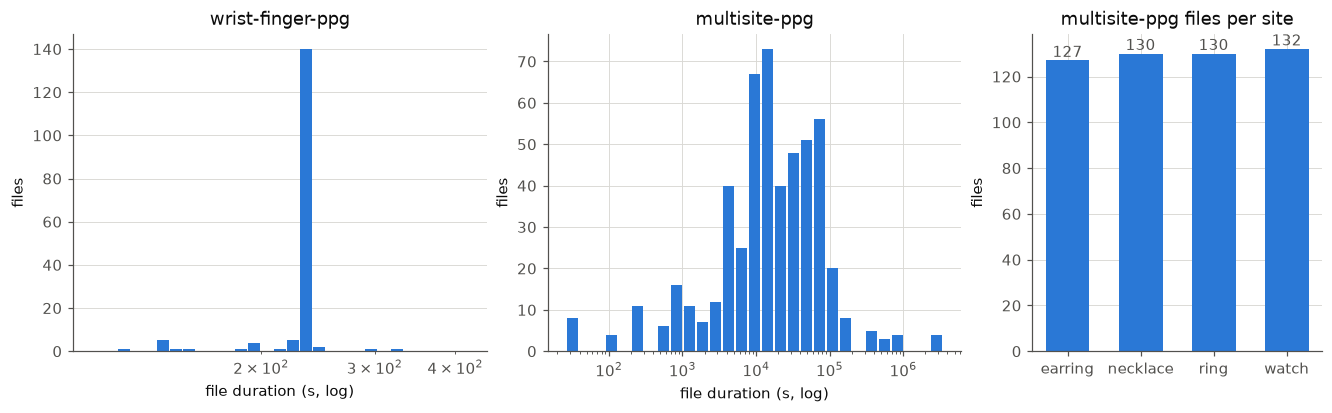

In [7]:
fig, axes = plt.subplots(1, 3, figsize=figsize(1.4), gridspec_kw={"width_ratios": [1, 1, 0.7]})
for ax, ds in zip(axes, DATASETS):
    d = manifest.loc[manifest.sub_dataset == ds, "duration_sec"].clip(lower=1)
    ax.hist(d, bins=np.logspace(np.log10(d.min()), np.log10(d.max()), 30), color=COLORS["real"], rwidth=0.9)
    ax.set_xscale("log")
    ax.set(title=ds, xlabel="file duration (s, log)", ylabel="files")
sites = manifest[manifest.sub_dataset == MULTISITE_DIR].groupby("site").size()
axes[2].bar(sites.index, sites.values, color=COLORS["real"], width=0.6)
for x, v in enumerate(sites.values):
    axes[2].text(x, v, str(v), ha="center", va="bottom", color=COLORS["muted"])
axes[2].set(title="multisite-ppg files per site", ylabel="files");

**What it shows:** file counts and recording length per sub-dataset, and the four wearable sites of `multisite-ppg`.

wrist-finger clips are a few minutes each. Multisite recordings span several orders of magnitude (seconds to days), which is why `cache.py` caps multisite windows at 2000 per subject; otherwise a few long files would dominate training.

## 2. Raw EDF signals

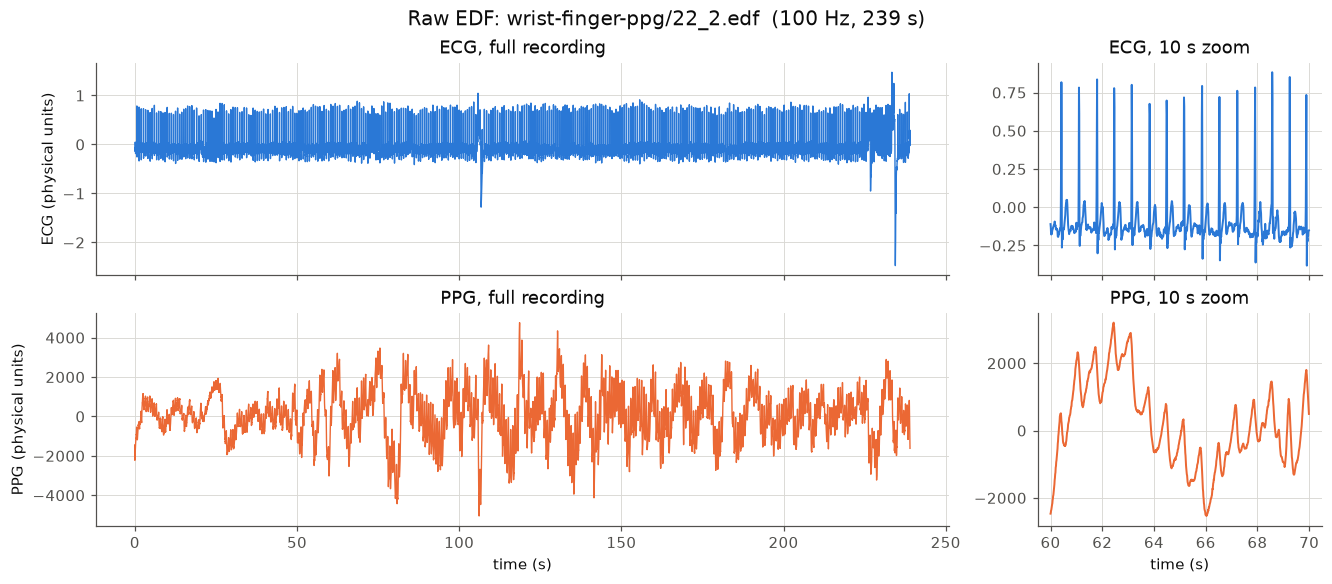

In [8]:
# demo file: wrist-finger file whose rejected share is closest to 10%, so every pipeline step has something to show
wf_scan = {k: v for k, v in SCAN.items() if v["sub_dataset"] == WRISTFINGER_DIR}
DEMO = min(wf_scan, key=lambda k: abs(wf_scan[k]["rejected"].mean() - 0.10))
demo = load_file(DEMO)
fs = demo["fs"]
t = np.arange(len(demo["ecg"])) / fs
ZOOM = (60, 70)

fig, axes = plt.subplots(2, 2, figsize=figsize(2), gridspec_kw={"width_ratios": [3, 1]}, sharex="col")
for r, (key, name, unit) in enumerate([("ecg", "ECG", "ECG"), ("ppg", "PPG", "PPG")]):
    for c, sl in enumerate([slice(None), slice(int(ZOOM[0] * fs), int(ZOOM[1] * fs))]):
        axes[r, c].plot(t[sl], demo[key][sl], color=COLORS[key], lw=STYLE["lw_thin"] if c == 0 else STYLE["lw"])
    axes[r, 0].set_ylabel(f"{name} (physical units)")
    axes[r, 0].set_title(f"{name}, full recording")
    axes[r, 1].set_title(f"{name}, {ZOOM[1] - ZOOM[0]} s zoom")
for ax in axes[1]:
    ax.set_xlabel("time (s)")
fig.suptitle(f"Raw EDF: {DEMO}  ({fs:.0f} Hz, {len(t) / fs:.0f} s)");

**What it shows:** the two channels of one raw EDF file, as read by `edf_io.read_channels` (digital values scaled to physical units). Every file is plain EDF at 100 Hz with an `ECG` and a `PPG` channel and no annotations, so the BPM labels have to be derived from the ECG.

## 3. Pipeline: ECG to HR label, PPG to model input

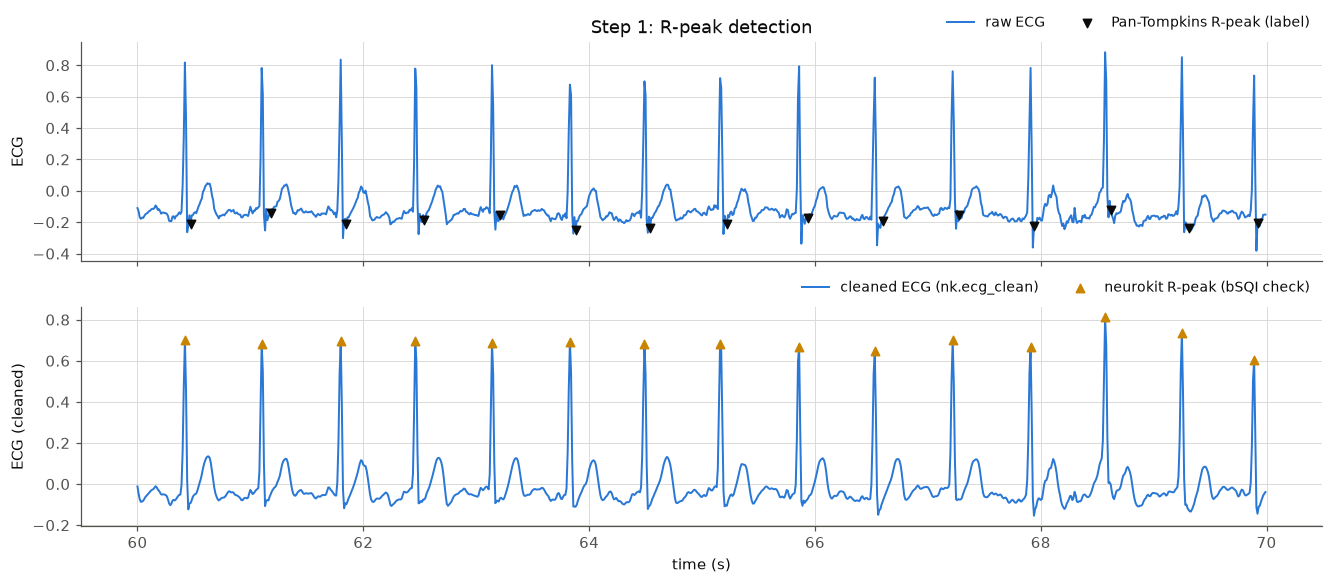

In [9]:
sl = slice(int(ZOOM[0] * fs), int(ZOOM[1] * fs))
fig, axes = plt.subplots(2, 1, figsize=figsize(2), sharex=True)
in_zoom = lambda p: p[(p >= sl.start) & (p < sl.stop)]
axes[0].plot(t[sl], demo["ecg"][sl], color=COLORS["ecg"], label="raw ECG")
p = in_zoom(demo["p1"])
axes[0].scatter(t[p], demo["ecg"][p], marker="v", s=STYLE["marker"], color=COLORS["rpeak"], zorder=3,
                label="Pan-Tompkins R-peak (label)")
axes[1].plot(t[sl], demo["cleaned"][sl], color=COLORS["ecg"], label="cleaned ECG (nk.ecg_clean)")
p = in_zoom(demo["p2"])
axes[1].scatter(t[p], demo["cleaned"][p], marker="^", s=STYLE["marker"], color=COLORS["rpeak_nk"], zorder=3,
                label="neurokit R-peak (bSQI check)")
axes[0].set(title="Step 1: R-peak detection", ylabel="ECG")
axes[1].set(xlabel="time (s)", ylabel="ECG (cleaned)")
for ax in axes:
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2)

**What it shows:** Pan-Tompkins (`ground_truth._neurokit2_r_peak_detector`) finds the R-peaks that define the label. A second detector (neurokit on the cleaned ECG) runs only as a cross-check: where the two disagree, the ECG is not trusted (bSQI gate).

Observation: Pan-Tompkins marks each beat ~50-70 ms *after* the R-peak (on the S-wave / return to baseline), and the lag varies beat to beat. A constant lag would not change RR intervals, but the variation adds RR jitter (beat-to-beat RR-difference SD ~60-80 ms vs ~20-35 ms for neurokit on the files checked), which makes the HR curve noisier and triggers extra `RR ratio > 1.2` rejections.

rejected seconds per gate: {'flat ECG': 0, 'bSQI < 0.8': 0, 'HR outside 30-220': 0, 'RR ratio > 1.2': 22, 'flat PPG': 0} | outside beats: 2 | total rejected: 24 of 239


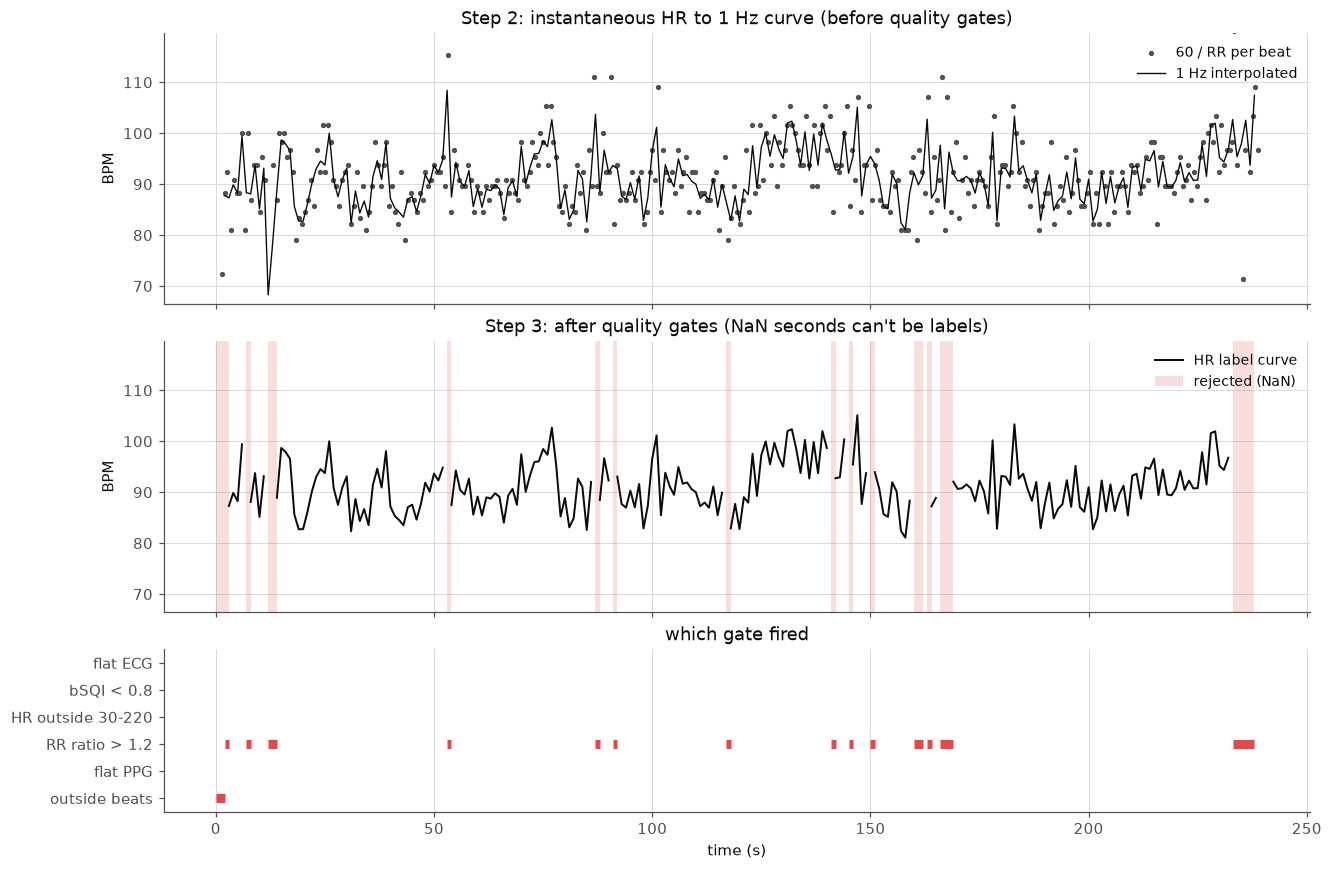

In [10]:
n = demo["n"]
fig, axes = plt.subplots(3, 1, figsize=figsize(3), sharex=True, gridspec_kw={"height_ratios": [1, 1, 0.6]})
axes[0].scatter(demo["p1"][1:] / fs, demo["inst_hr"], s=6, color=COLORS["muted"], label="60 / RR per beat")
axes[0].plot(np.arange(n), demo["raw_curve"], color=COLORS["hr"], lw=STYLE["lw_thin"], label="1 Hz interpolated")
axes[0].set(title="Step 2: instantaneous HR to 1 Hz curve (before quality gates)", ylabel="BPM")
axes[1].plot(np.arange(n), demo["curve"], color=COLORS["hr"], label="HR label curve")
shade_seconds(axes[1], demo["rejected"])
axes[1].set(title="Step 3: after quality gates (NaN seconds can't be labels)", ylabel="BPM")
for i, gname in enumerate(GATES + ["outside beats"]):
    m = demo["outside"] if gname == "outside beats" else demo["masks"][gname]
    for a, b in runs(m):
        axes[2].plot([a, b], [i, i], color=COLORS["rejected"], lw=6, solid_capstyle="butt")
axes[2].set_yticks(range(len(GATES) + 1), GATES + ["outside beats"])
axes[2].set_ylim(len(GATES) + 0.5, -0.5)
axes[2].grid(axis="y", visible=False)
axes[2].set(title="which gate fired", xlabel="time (s)")
for ax in axes[:2]:
    ax.legend(loc="upper right")
lo = np.nanpercentile(demo["raw_curve"], 1) - 15
axes[0].set_ylim(max(20, lo), np.nanpercentile(demo["raw_curve"], 99) + 15)
axes[1].set_ylim(axes[0].get_ylim())
print("rejected seconds per gate:", {g: int(m.sum()) for g, m in demo["masks"].items()},
      "| outside beats:", int(demo["outside"].sum()), "| total rejected:", int(demo["rejected"].sum()), "of", n)

**What it shows:** each beat gives an instantaneous HR (60 / RR), linearly interpolated to a 1 Hz curve (`ecg_to_hr_curve`). The quality gates then set unusable seconds to NaN; the bottom strip shows which gate removed which second (gates overlap). Windows that touch a NaN second are dropped in step 5.

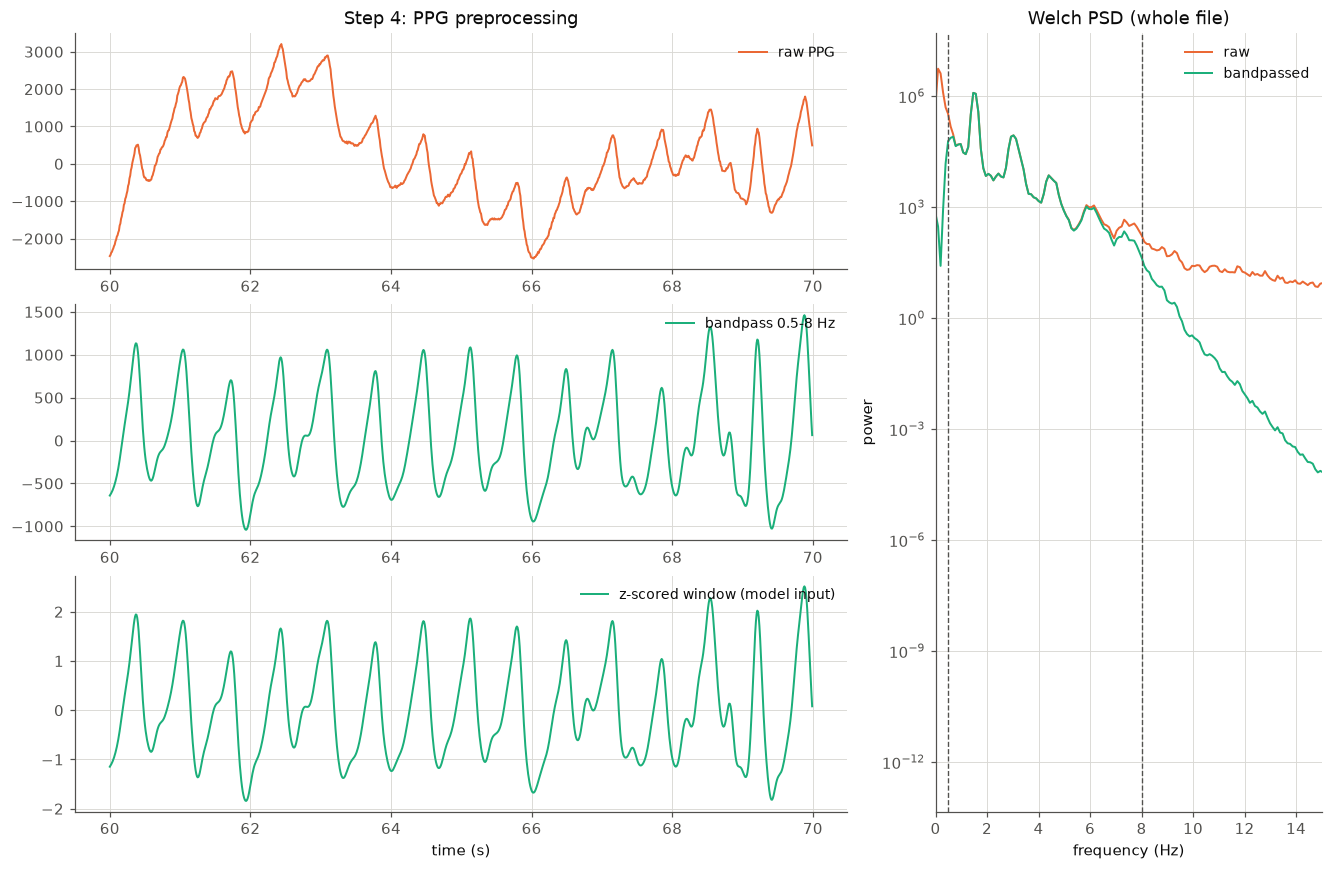

In [11]:
f_raw, p_raw = welch(demo["ppg"], fs, nperseg=1024)
f_bp, p_bp = welch(demo["ppg_bp"], fs, nperseg=1024)
fig = plt.figure(figsize=figsize(3))
gs = fig.add_gridspec(3, 2, width_ratios=[2, 1])
ax_raw, ax_bp, ax_z = (fig.add_subplot(gs[i, 0]) for i in range(3))
ax_psd = fig.add_subplot(gs[:, 1])
ax_raw.plot(t[sl], demo["ppg"][sl], color=COLORS["ppg"], label="raw PPG")
ax_bp.plot(t[sl], demo["ppg_bp"][sl], color=COLORS["ppg_filtered"], label="bandpass 0.5-8 Hz")
win = demo["ppg_bp"][sl]
ax_z.plot(t[sl], zscore_window(win[None])[0], color=COLORS["ppg_filtered"], label="z-scored window (model input)")
ax_raw.set_title("Step 4: PPG preprocessing")
ax_z.set_xlabel("time (s)")
for ax in (ax_raw, ax_bp, ax_z):
    ax.legend(loc="upper right")
ax_psd.semilogy(f_raw, p_raw, color=COLORS["ppg"], label="raw")
ax_psd.semilogy(f_bp, p_bp, color=COLORS["ppg_filtered"], label="bandpassed")
for fc in (0.5, 8):
    ax_psd.axvline(fc, color=COLORS["muted"], ls="--", lw=STYLE["lw_thin"])
ax_psd.set(title="Welch PSD (whole file)", xlabel="frequency (Hz)", ylabel="power", xlim=(0, 15))
ax_psd.legend(loc="upper right");

**What it shows:** the 4th-order Butterworth bandpass (0.5-8 Hz, zero-phase `sosfiltfilt`, applied to the whole file) removes baseline wander and DC (below 0.5 Hz) and high-frequency noise (above 8 Hz) while keeping the pulse fundamental (~1-3 Hz) and its harmonics. Each window is z-scored (`dataset.zscore_window`) just before it enters the model, so amplitude differences between sensors don't matter.

## 4. Window creation

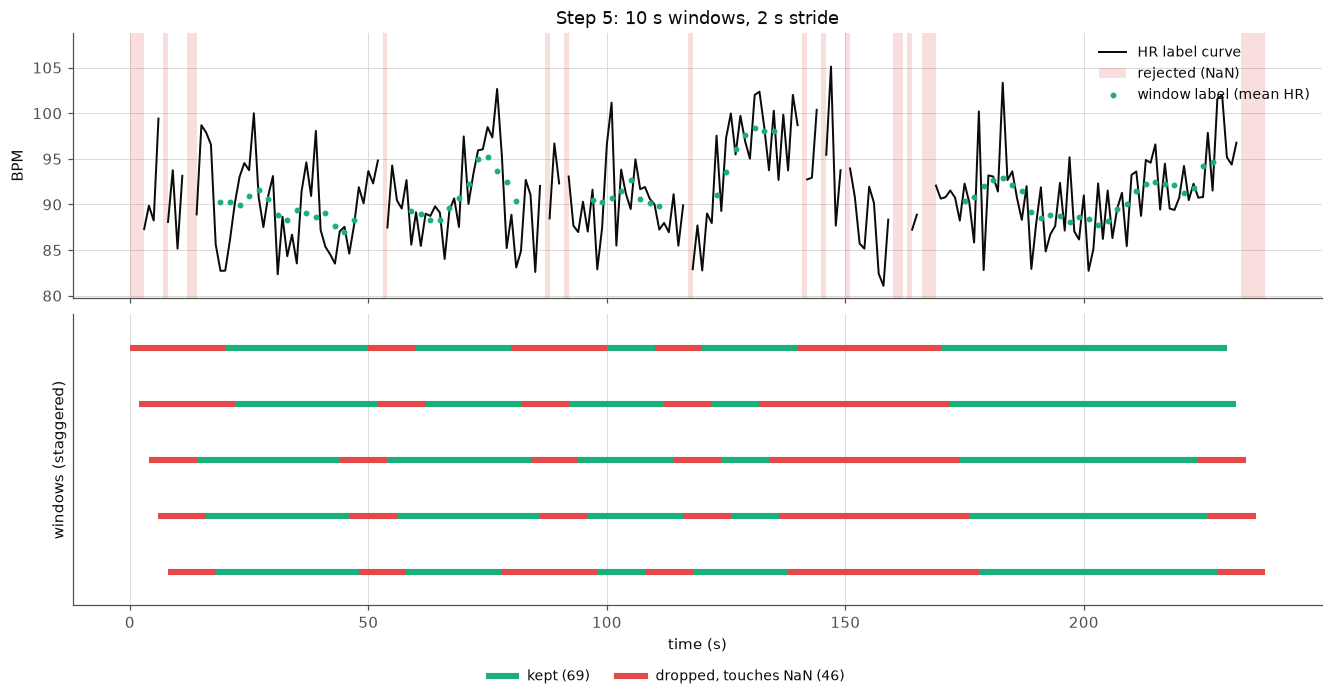

In [12]:
windows, labels = make_windows({"PPG": demo["ppg_bp"]}, demo["curve"], fs, window_s=WINDOW_S, stride_s=STRIDE_S)
starts = np.arange(0, n - WINDOW_S + 1, STRIDE_S)
kept = np.array([not np.isnan(demo["curve"][s : s + WINDOW_S]).any() for s in starts])
assert kept.sum() == len(labels)

fig, axes = plt.subplots(2, 1, figsize=figsize(2.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
axes[0].plot(np.arange(n), demo["curve"], color=COLORS["hr"], label="HR label curve")
shade_seconds(axes[0], demo["rejected"])
axes[0].scatter(starts[kept] + WINDOW_S / 2, labels, s=8, color=COLORS["kept"], zorder=3, label="window label (mean HR)")
axes[0].set(title=f"Step 5: {WINDOW_S} s windows, {STRIDE_S} s stride", ylabel="BPM")
axes[0].legend(loc="upper right")
lanes = WINDOW_S // STRIDE_S
for i, (s, k) in enumerate(zip(starts, kept)):
    axes[1].plot([s, s + WINDOW_S], [i % lanes] * 2, lw=4, solid_capstyle="butt",
                 color=COLORS["kept"] if k else COLORS["rejected"])
axes[1].plot([], [], lw=4, color=COLORS["kept"], label=f"kept ({kept.sum()})")
axes[1].plot([], [], lw=4, color=COLORS["rejected"], label=f"dropped, touches NaN ({(~kept).sum()})")
axes[1].set_yticks([])
axes[1].set(xlabel="time (s)", ylabel="windows (staggered)")
axes[1].set_ylim(lanes - 0.4, -0.6)
fig.legend(handles=axes[1].get_lines()[-2:], loc="outside lower center", ncol=2);

**What it shows:** `make_windows` slides a 10 s window in 2 s steps over the bandpassed PPG. A window is kept only if all 10 seconds of the HR curve are valid; its label is the mean HR over those 10 seconds. Neighbouring windows overlap by 8 s, so they are strongly correlated (one reason the split is subject-wise).

In [13]:
def plot_window(g, start_s, title, ctx=10, spectrum=False):
    """ECG + R-peaks, bandpassed PPG, HR curve and gate strip around one 10 s window."""
    fs, n = g["fs"], g["n"]
    a, b = max(0, start_s - ctx), min(n, start_s + WINDOW_S + ctx)
    sl = slice(int(a * fs), int(b * fs))
    tt = np.arange(sl.start, sl.stop) / fs
    fig = plt.figure(figsize=figsize(3.4))
    gs = fig.add_gridspec(4, 2 if spectrum else 1, height_ratios=[1, 1, 1, 0.75],
                          width_ratios=[3, 1] if spectrum else [1])
    axes = [fig.add_subplot(gs[0, 0])]
    axes += [fig.add_subplot(gs[i, 0], sharex=axes[0]) for i in range(1, 4)]
    ax_ecg, ax_ppg, ax_hr, ax_g = axes

    ax_ecg.plot(tt, g["ecg"][sl], color=COLORS["ecg"], lw=STYLE["lw_thin"], label="ECG")
    for key, m, col, lab in [("p1", "v", "rpeak", "Pan-Tompkins"), ("p2", "^", "rpeak_nk", "neurokit")]:
        p = g[key][(g[key] >= sl.start) & (g[key] < sl.stop)]
        ax_ecg.scatter(p / fs, g["ecg"][p], marker=m, s=STYLE["marker"], color=COLORS[col], zorder=3, label=lab)
    ax_ppg.plot(tt, g["ppg_bp"][sl], color=COLORS["ppg_filtered"], lw=STYLE["lw_thin"], label="PPG (bandpassed)")
    secs = np.arange(a, b)
    ax_hr.plot(secs, g["raw_curve"][a:b], color=COLORS["muted"], lw=STYLE["lw_thin"], ls=":", label="HR before gates")
    ax_hr.plot(secs, g["curve"][a:b], color=COLORS["hr"], label="HR label curve")
    shade_seconds(ax_hr, g["rejected"][a:b], t0=a)
    names = GATES + ["outside beats"]
    for i, gname in enumerate(names):
        m = (g["outside"] if gname == "outside beats" else g["masks"][gname])[a:b]
        for x0, x1 in runs(m):
            ax_g.plot([a + x0, a + x1], [i, i], color=COLORS["rejected"], lw=6, solid_capstyle="butt")
    ax_g.set_yticks(range(len(names)), names)
    ax_g.set_ylim(len(names) - 0.5, -0.5)
    ax_g.grid(axis="y", visible=False)
    ax_ecg.set_ylabel("ECG")
    ax_ppg.set_ylabel("PPG")
    ax_hr.set_ylabel("BPM")
    ax_g.set_xlabel("time in file (s)")
    handles = [h for ax in (ax_ecg, ax_ppg, ax_hr) for h in ax.get_legend_handles_labels()[0]]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    for ax in (ax_ecg, ax_ppg, ax_hr):
        plt.setp(ax.get_xticklabels(), visible=False)
    if np.isnan(g["raw_curve"][a:b]).all():
        ax_hr.set_ylim(40, 120)
    mark_window(axes, start_s)

    hr_win = g["curve"][start_s : start_s + WINDOW_S]
    label = "dropped" if np.isnan(hr_win).any() else f"{hr_win.mean():.1f} BPM"
    fired = [gname for gname in names
             if (g["outside"] if gname == "outside beats" else g["masks"][gname])[start_s : start_s + WINDOW_S].any()]
    rate = None
    if spectrum:
        w = g["ppg_bp"][int(start_s * fs) : int((start_s + WINDOW_S) * fs)]
        rate, bpm, power = ppg_rate(w, fs)
        ax_s = fig.add_subplot(gs[:, 1])
        ax_s.plot(bpm, power / power.max(), color=COLORS["ppg_filtered"], label="PPG spectrum (window)")
        ax_s.axvline(rate, color=COLORS["ppg"], ls="--", label=f"PPG peak {rate:.0f} BPM")
        if not np.isnan(hr_win).any():
            ax_s.axvline(hr_win.mean(), color=COLORS["ecg"], label=f"ECG label {hr_win.mean():.0f} BPM")
        ax_s.axvspan(0, 36, color=COLORS["muted"], alpha=STYLE["alpha_window"], lw=0)
        ax_s.axvspan(210, 240, color=COLORS["muted"], alpha=STYLE["alpha_window"], lw=0)
        ax_s.set(xlim=(0, 240), xlabel="BPM (60 × Hz)", ylabel="relative power", title="window spectrum")
        ax_s.legend(loc="upper right")
    fig.suptitle(f"{title}\n{g['path']}, window {start_s}-{start_s + WINDOW_S} s: label {label}"
                 + (f" | gates fired: {', '.join(fired)}" if fired else " | all gates pass"))
    return rate

### Good window

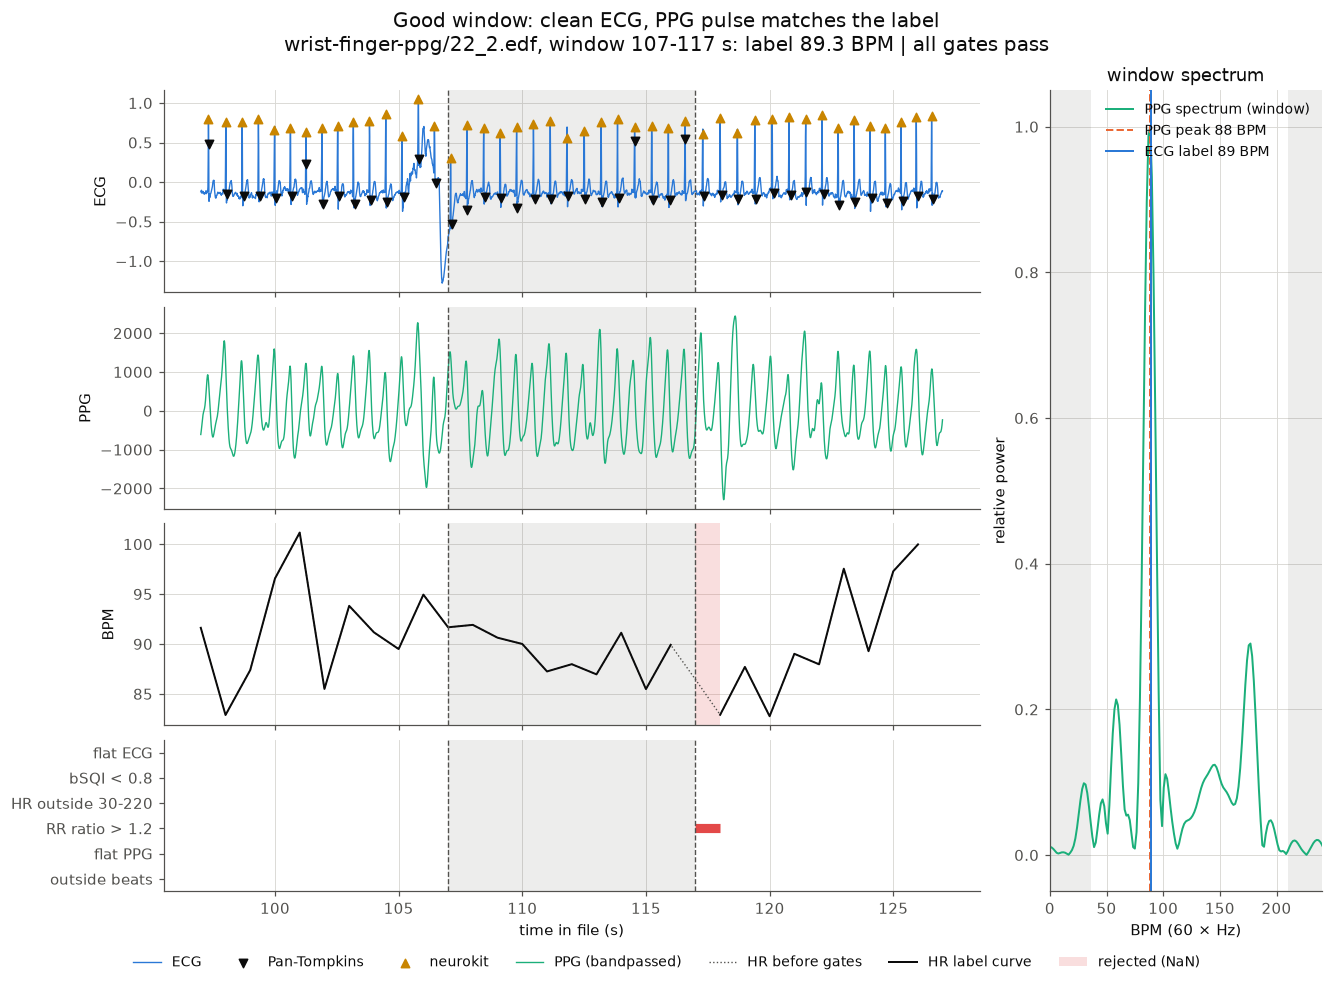

In [14]:
agree = ppg_hr_agrees(demo["ppg_bp"], demo["curve"], fs)
clean = np.array([not np.isnan(demo["curve"][s : s + WINDOW_S]).any() for s in range(len(agree))])
good = np.flatnonzero(clean & agree)
GOOD_START = int(good[len(good) // 2])
plot_window(demo, GOOD_START, "Good window: clean ECG, PPG pulse matches the label", spectrum=True);

**What it shows:** a window that passes every gate. Both R-peak detectors mark the same beats, the HR curve is continuous, and the PPG spectral peak (right) sits on the ECG label: the PPG carries the information the model needs.

### Windows rejected by the quality gates

One example per gate, picked automatically from the scanned files. The search prefers a window where only that gate fires; the gate strip at the bottom shows which gates fired around it.

In [15]:
rng = np.random.default_rng(0)


def find_gate_example(gate):
    """Window where `gate` fires inside the beat range; fewest other gates firing nearby wins."""
    cands = []  # (n other gates firing within +-10 s, rel, start)
    for rel, s in SCAN.items():
        for a, _ in runs(s["masks"][gate]):
            start = int(a) - 3
            if start < 10 or start + WINDOW_S + 10 > s["n"] or s["outside"][start : start + WINDOW_S].any():
                continue
            ctx = slice(start - 10, start + WINDOW_S + 10)
            n_other = sum(s["masks"][o][ctx].any() for o in GATES if o != gate) + s["outside"][ctx].any()
            cands.append((n_other, rel, start))
    if not cands:
        return None, None
    best = min(c[0] for c in cands)
    pool = [c for c in cands if c[0] == best]
    _, rel, start = pool[rng.integers(len(pool))]
    return (rel, start), best


GATE_EXAMPLES = {}
for gate in GATES:
    hit, n_other = find_gate_example(gate)
    GATE_EXAMPLES[gate] = hit
    print(f"{gate:>18}: {hit if hit else 'no example in scanned files'}"
          + (f" ({n_other} other gates fire nearby)" if hit else ""))

          flat ECG: ('multisite-ppg/P12_watch_1.edf', 6041) (3 other gates fire nearby)
        bSQI < 0.8: ('multisite-ppg/P19_watch_1.edf', 11897) (1 other gates fire nearby)
 HR outside 30-220: ('multisite-ppg/P14_watch_2.edf', 1304) (1 other gates fire nearby)
    RR ratio > 1.2: ('multisite-ppg/P20_watch_7.edf', 3989) (0 other gates fire nearby)


          flat PPG: ('multisite-ppg/P20_earring_7.edf', 688) (0 other gates fire nearby)


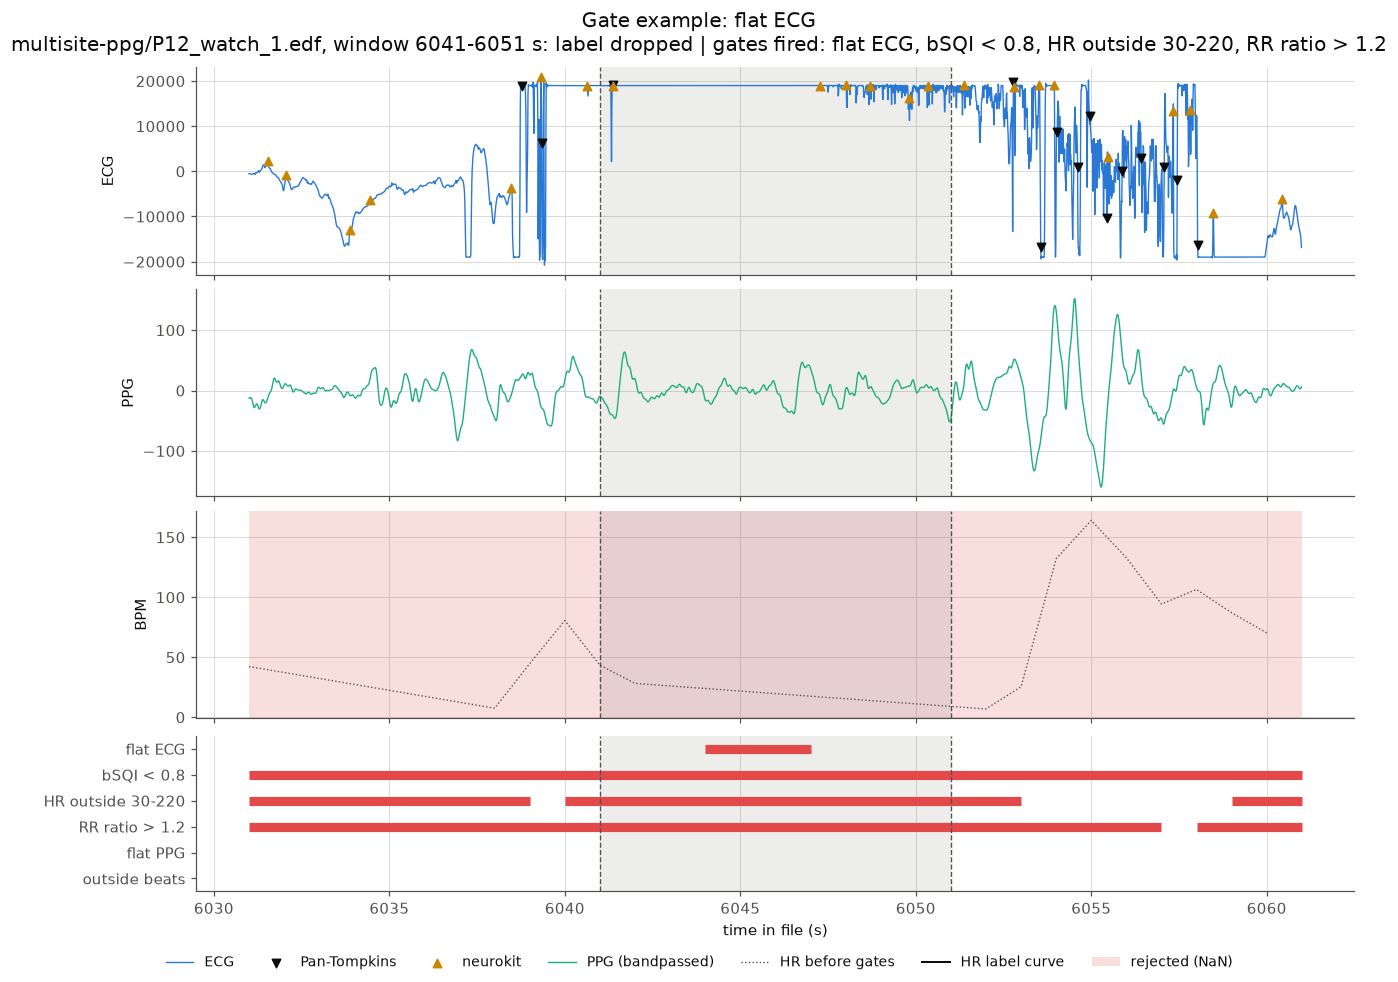

In [16]:
gate = 'flat ECG'
if GATE_EXAMPLES[gate]:
    rel, start = GATE_EXAMPLES[gate]
    plot_window(load_file(rel), start, f"Gate example: {gate}")

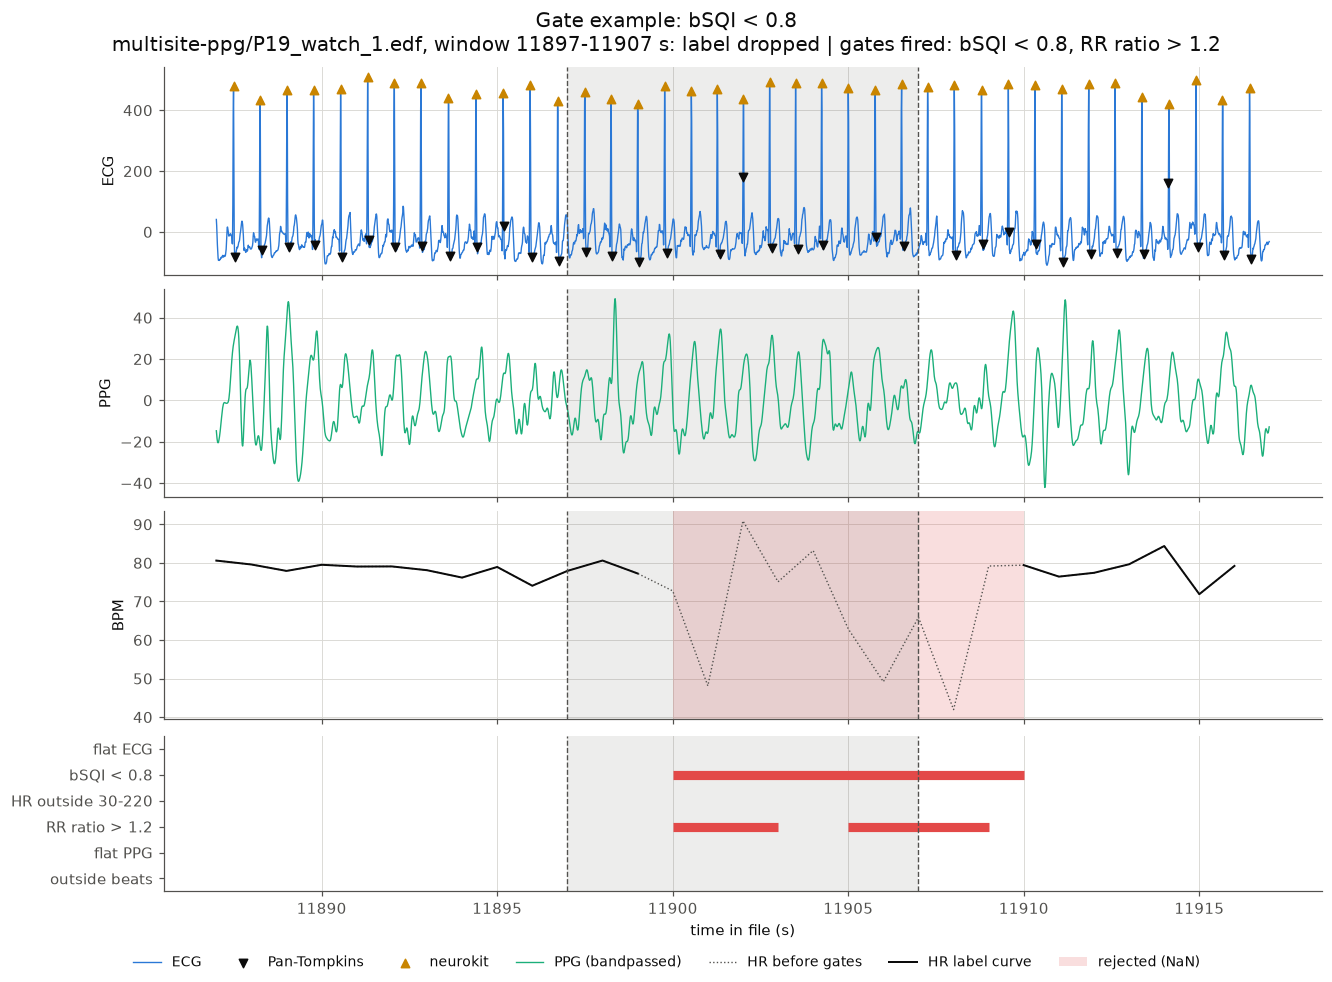

In [17]:
gate = 'bSQI < 0.8'
if GATE_EXAMPLES[gate]:
    rel, start = GATE_EXAMPLES[gate]
    plot_window(load_file(rel), start, f"Gate example: {gate}")

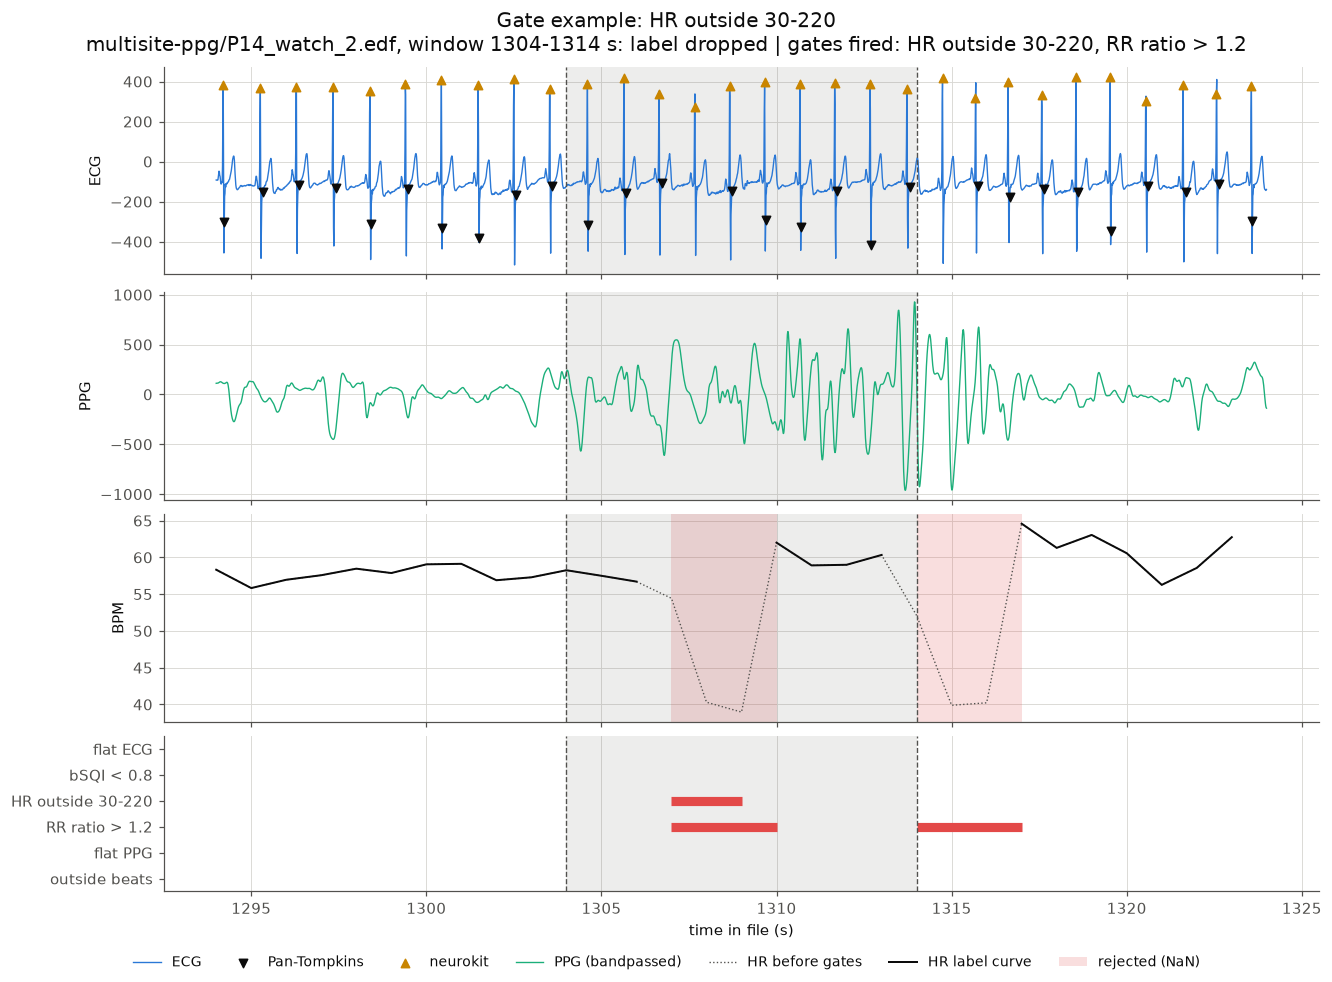

In [18]:
gate = 'HR outside 30-220'
if GATE_EXAMPLES[gate]:
    rel, start = GATE_EXAMPLES[gate]
    plot_window(load_file(rel), start, f"Gate example: {gate}")

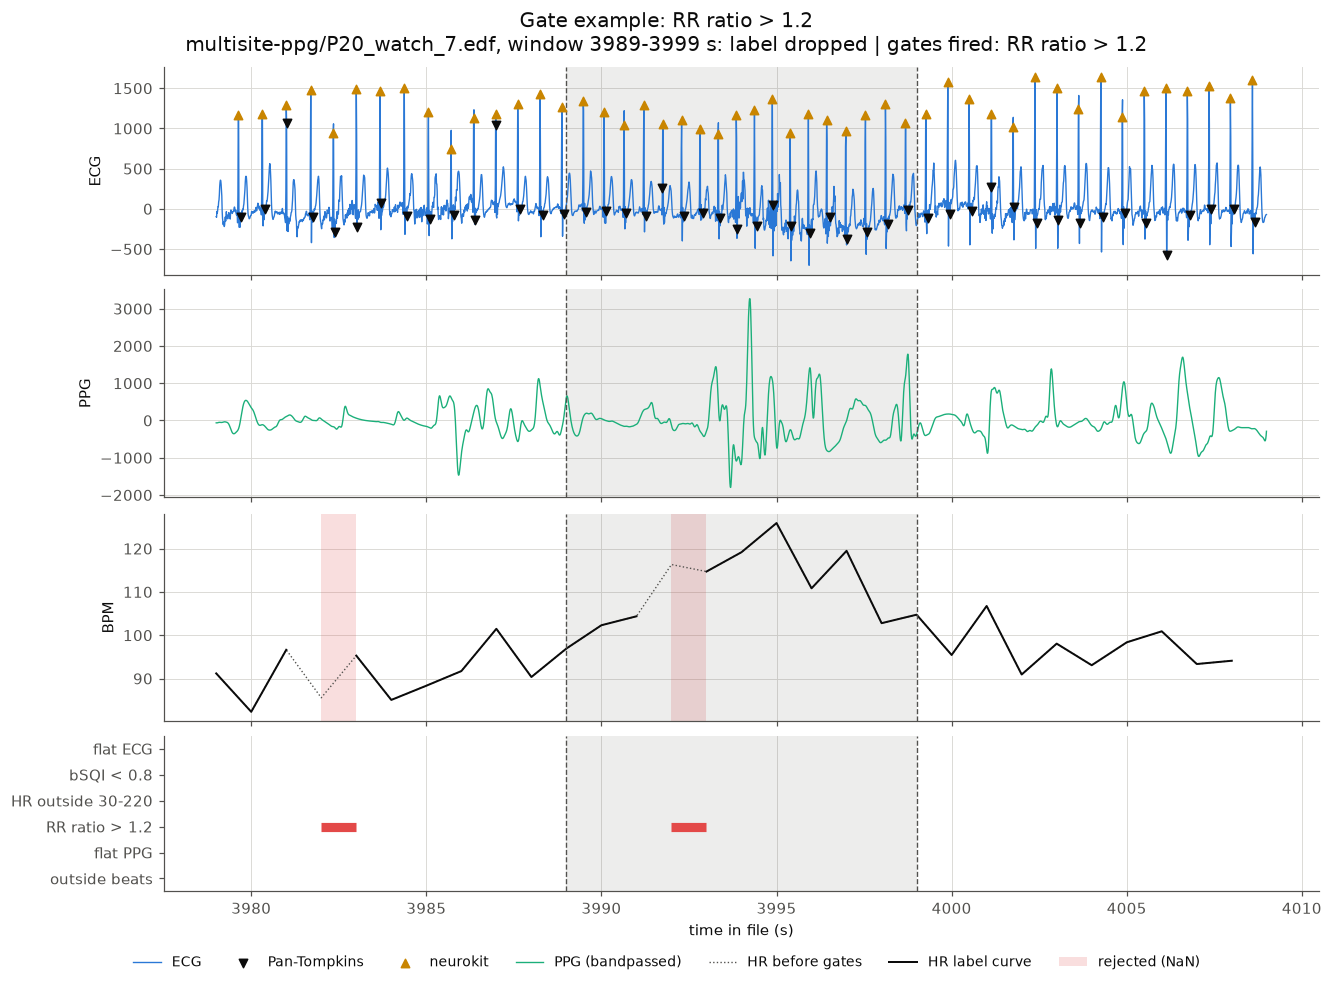

In [19]:
gate = 'RR ratio > 1.2'
if GATE_EXAMPLES[gate]:
    rel, start = GATE_EXAMPLES[gate]
    plot_window(load_file(rel), start, f"Gate example: {gate}")

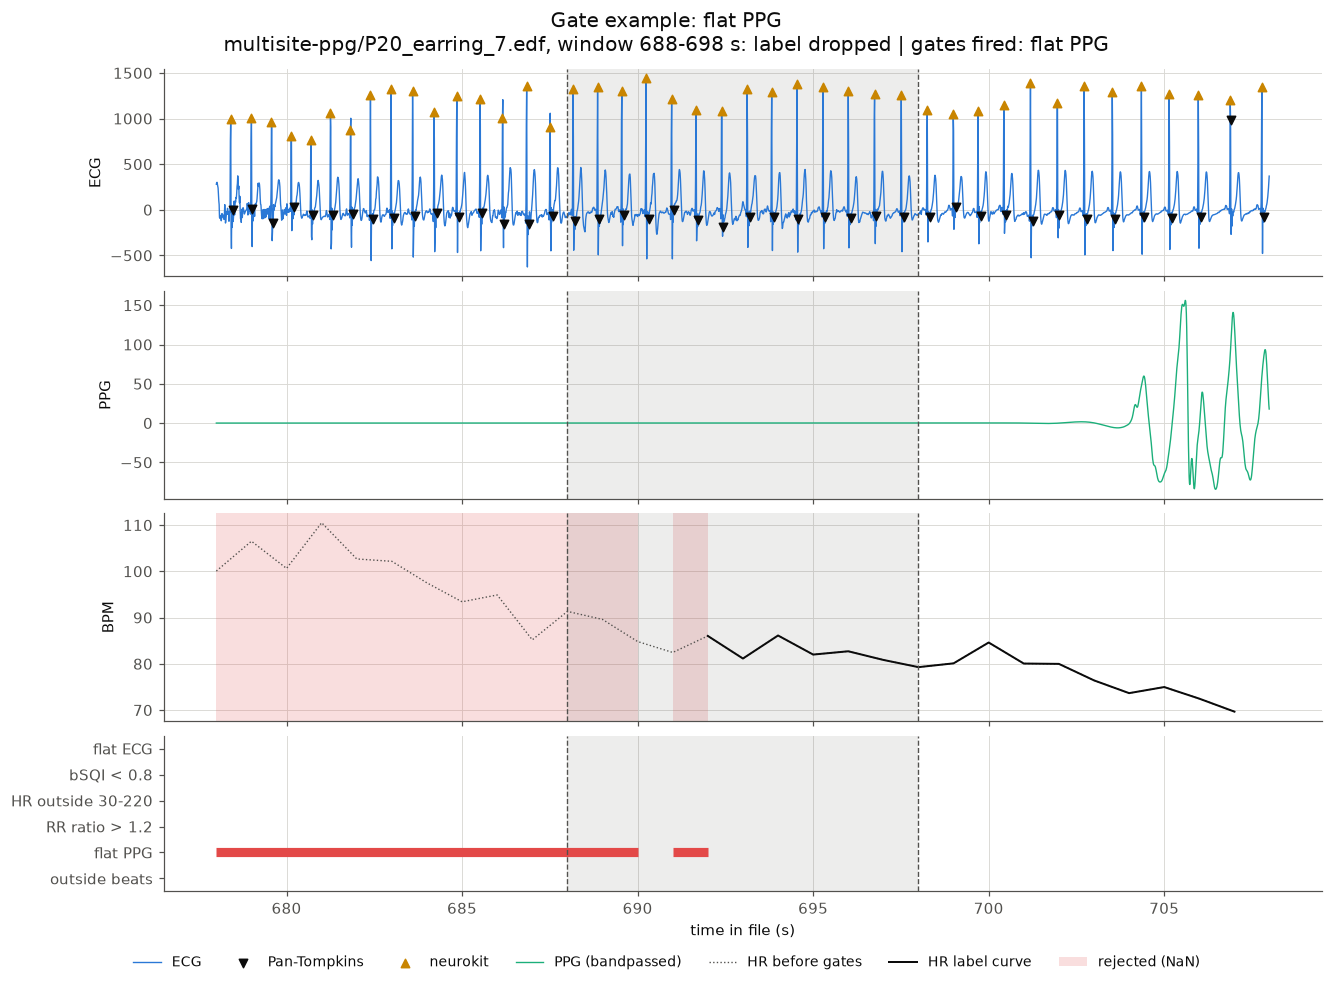

In [20]:
gate = 'flat PPG'
if GATE_EXAMPLES[gate]:
    rel, start = GATE_EXAMPLES[gate]
    plot_window(load_file(rel), start, f"Gate example: {gate}")

**What they show:**
- **flat ECG**: the cleaned ECG is near flat (lead off / saturated electrode); any "beats" found there are fake.
- **bSQI < 0.8**: the two R-peak detectors mark different beats, typical for noisy ECG; the whole 10 s bSQI block is dropped.
- **HR outside 30-220**: a missed or spurious R-peak produces an impossible instantaneous HR.
- **RR ratio > 1.2**: one RR interval jumps against the previous one (missed or extra beat, ectopic beat); the span between the affected beats is dropped.
- **flat PPG**: the raw PPG is constant (sensor off or padding), so no pulse exists even if the ECG is fine.

### Bad window: valid ECG label, unusable PPG

The gates check only the ECG (and fully flat PPG). A window can pass all of them while its PPG is dominated by motion artifacts. Such windows stay in the training data on purpose (realistic hard examples), but they cap what any PPG model can achieve. Found here via `timewarp.ppg_hr_agrees`: clean label, PPG spectral peak more than 30% away from it.

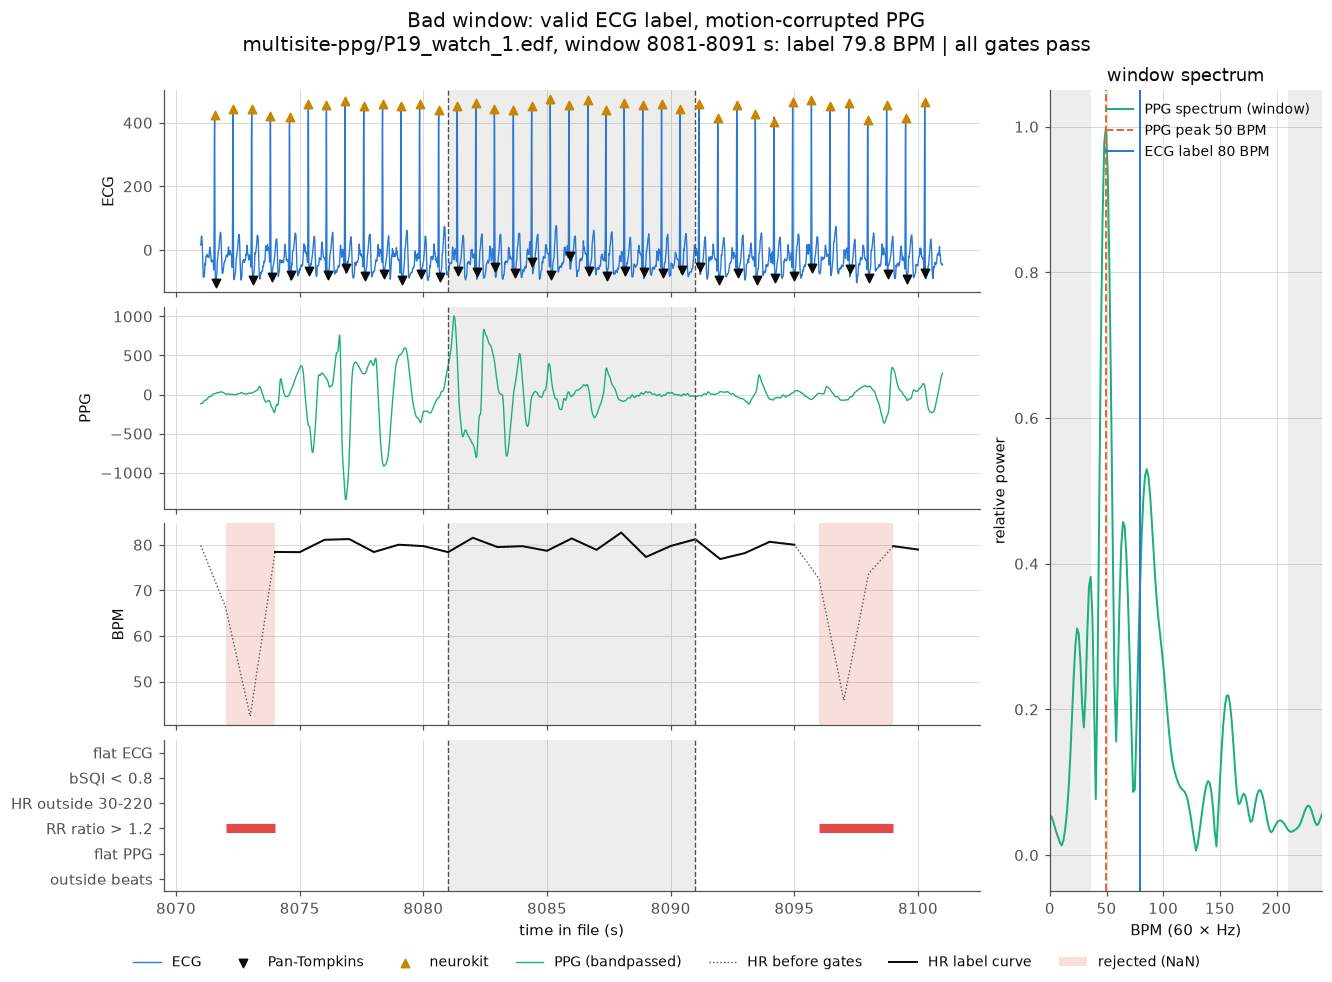

In [21]:
bad_pool = []
for rel in ms_sample.file_path:
    s = SCAN[rel]
    clean_s = np.array([not s["rejected"][k : k + WINDOW_S].any() for k in range(s["n"] - WINDOW_S + 1)])
    bad_pool += [(rel, int(k)) for k in np.flatnonzero(clean_s)[::50]]
rng.shuffle(bad_pool)

BAD, loaded = None, {}
for rel, start in bad_pool[:3000]:
    if rel not in loaded:
        loaded[rel] = load_file(rel)
    g = loaded[rel]
    w = g["ppg_bp"][int(start * g["fs"]) : int((start + WINDOW_S) * g["fs"])]
    label = g["curve"][start : start + WINDOW_S].mean()
    rate, *_ = ppg_rate(w, g["fs"])
    sl_w = slice(int(start * g["fs"]), int((start + WINDOW_S) * g["fs"]))
    sec_ptp = np.ptp(w.reshape(WINDOW_S, -1), axis=1)
    # spiky cleaned ECG = visible QRS complexes (baseline wander passes the gates too); PPG active in every second
    ecg_ok = kurtosis(g["cleaned"][sl_w]) > 5
    ppg_active = sec_ptp.min() > 0.3 * np.median(np.ptp(g["ppg_bp"][: g["n"] * int(g["fs"])].reshape(g["n"], -1), axis=1))
    if abs(rate - label) > 0.3 * label and ecg_ok and ppg_active:
        BAD = (g, start)
        break
plot_window(BAD[0], BAD[1], "Bad window: valid ECG label, motion-corrupted PPG", spectrum=True);

**What it shows:** the ECG is clean (detectors agree, no gate fires), so the label is right. The PPG, however, has no clear pulse at the ECG rate: its spectral peak lies far from the label. Multisite (free-living) recordings contain many of these; this is the main reason the model does much worse on `multisite-ppg` than on `wrist-finger-ppg`.

### Time-warp bootstrap

`timewarp.warp_window` resamples a source span of `10 × f` seconds into one 10 s window, so the pulse rate and the label scale by `f`. `f < 1` stretches (lower BPM, used for the `L` bins 40-60), `f > 1` squeezes (higher BPM, used for the `H` bins 110-190). The warped signal is bandpassed again, because warping shifts the 0.5-8 Hz band. Both examples use the same clean source start of the demo file.

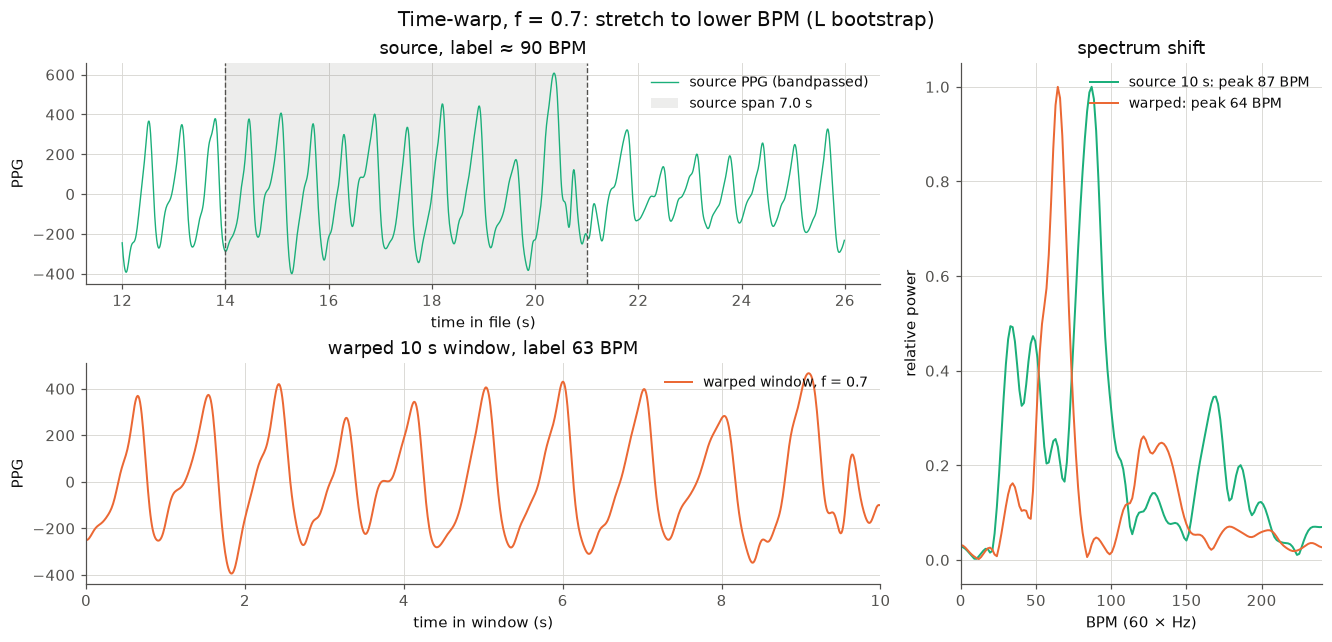

In [22]:
def plot_warp(g, start_s, factor, title):
    fs = g["fs"]
    out = warp_window(g["ppg_bp"], g["curve"], fs, start_s, factor)
    assert out is not None, "source span hits NaN or file edge"
    warped, label = out
    src_label = g["curve"][start_s : start_s + WINDOW_S].mean()
    span = WINDOW_S * factor
    a, b = start_s - 2, start_s + max(span, WINDOW_S) + 2
    tt = np.arange(int(a * fs), int(b * fs)) / fs
    fig = plt.figure(figsize=figsize(2.2))
    gs = fig.add_gridspec(2, 2, width_ratios=[2.2, 1])
    ax_src, ax_w = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
    ax_s = fig.add_subplot(gs[:, 1])
    ax_src.plot(tt, g["ppg_bp"][int(a * fs) : int(b * fs)], color=COLORS["ppg_filtered"], lw=STYLE["lw_thin"],
                label="source PPG (bandpassed)")
    ax_src.axvspan(start_s, start_s + span, color=COLORS["window"], alpha=STYLE["alpha_window"], lw=0,
                   label=f"source span {span:.1f} s")
    for x in (start_s, start_s + span):
        ax_src.axvline(x, color=COLORS["window"], ls="--", lw=STYLE["lw_thin"])
    ax_src.set(title=f"source, label ≈ {src_label:.0f} BPM", xlabel="time in file (s)", ylabel="PPG")
    ax_w.plot(np.arange(warped.shape[1]) / fs, warped[0], color=COLORS["boot"],
              label=f"warped window, f = {factor}")
    ax_w.set(title=f"warped 10 s window, label {label:.0f} BPM", xlabel="time in window (s)", ylabel="PPG",
             xlim=(0, WINDOW_S))
    for ax in (ax_src, ax_w):
        ax.legend(loc="upper right")
    src_w = g["ppg_bp"][int(start_s * fs) : int((start_s + WINDOW_S) * fs)]
    for w, col, lab in [(src_w, COLORS["ppg_filtered"], "source 10 s"),
                        (warped[0], COLORS["boot"], "warped")]:
        rate, bpm, power = ppg_rate(w, fs)
        ax_s.plot(bpm, power / power.max(), color=col, label=f"{lab}: peak {rate:.0f} BPM")
    ax_s.set(xlim=(0, 240), xlabel="BPM (60 × Hz)", ylabel="relative power", title="spectrum shift")
    ax_s.legend(loc="upper right")
    fig.suptitle(title)


# a clean start whose stretched (f=0.7) and squeezed (f=1.6) spans both stay inside valid seconds
WARP_START = next(int(s) for s in good if source_label(demo["curve"], s, 1.6) and source_label(demo["curve"], s, 0.7))
plot_warp(demo, WARP_START, 0.7, "Time-warp, f = 0.7: stretch to lower BPM (L bootstrap)")

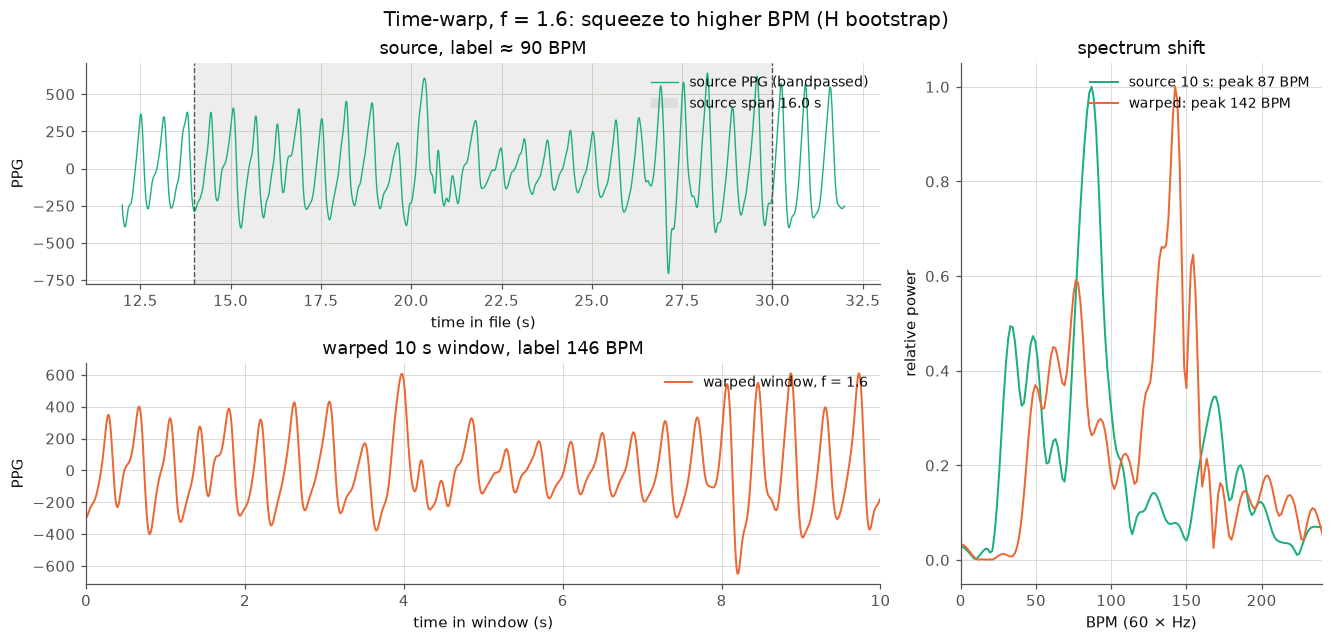

In [23]:
plot_warp(demo, WARP_START, 1.6, "Time-warp, f = 1.6: squeeze to higher BPM (H bootstrap)")

**What they show:** with `f = 0.7` a 7 s source span is stretched to 10 s, so beats are farther apart and the label drops to 0.7× the source HR. With `f = 1.6` a 16 s span is squeezed into 10 s and the label rises to 1.6×. The spectra on the right confirm the pulse peak moves by the same factor. Caveat: a uniform warp also scales pulse shape and systole, while real tachycardia mostly shortens diastole, so synthetic windows are an approximation.

## 5. Quality-gate rejection rates

,flat ECG,bSQI < 0.8,HR outside 30-220,RR ratio > 1.2,flat PPG,outside beats,any gate,windows kept
sub_dataset,,,,,,,,
multisite-ppg,9.2,58.1,35.4,40.7,23.9,18.0,64.9,21.0
wrist-finger-ppg,0.0,3.3,1.5,4.4,0.0,2.0,6.7,76.6


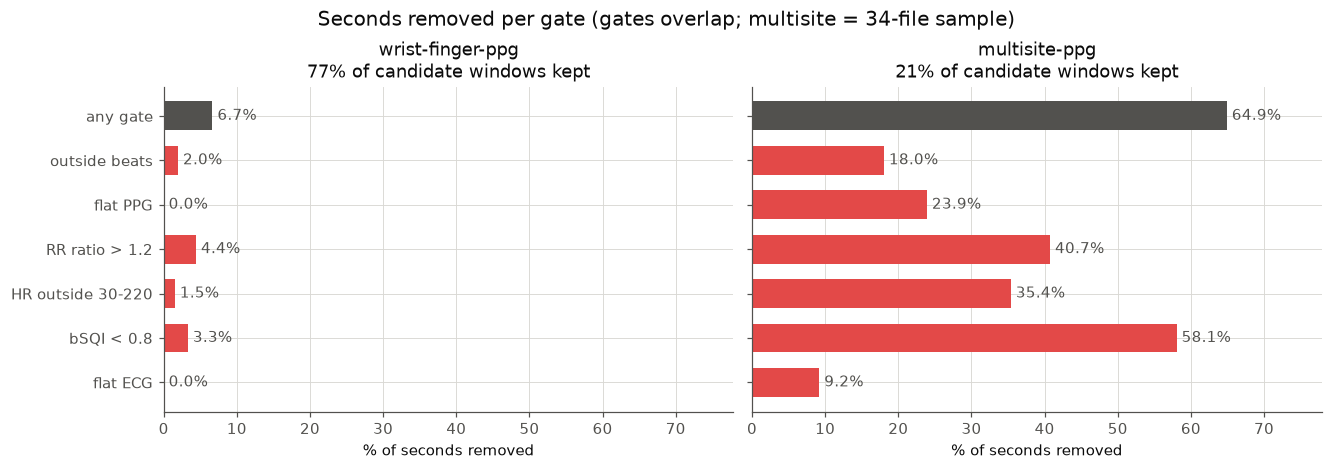

In [24]:
fig, axes = plt.subplots(1, 2, figsize=figsize(1.6), sharey=True)
for ax, ds in zip(axes, DATASETS):
    v = share.loc[ds, cols]
    y = np.arange(len(cols))
    ax.barh(y, v.values, color=[COLORS["rejected"]] * (len(cols) - 1) + [COLORS["muted"]], height=0.65)
    for yi, val in zip(y, v.values):
        ax.text(val, yi, f" {val:.1f}%", va="center", color=COLORS["muted"])
    ax.set_yticks(y, cols)
    ax.invert_yaxis()
    ax.set_xlim(0, max(share[cols].max().max() * 1.2, 5))
    ax.set(title=f"{ds}\n{share.loc[ds, 'windows kept']:.0f}% of candidate windows kept",
           xlabel="% of seconds removed")
fig.suptitle(f"Seconds removed per gate (gates overlap; multisite = {len(ms_sample)}-file sample)")
share.round(1)

**What it shows:** the share of seconds each gate removes, per sub-dataset (a second can be removed by several gates, so the bars don't add up; the gray bar is the union). The title gives the share of candidate 10 s windows that survive. Because one bad second drops five overlapping windows, the window loss is larger than the seconds loss.

## 6. BPM label distribution

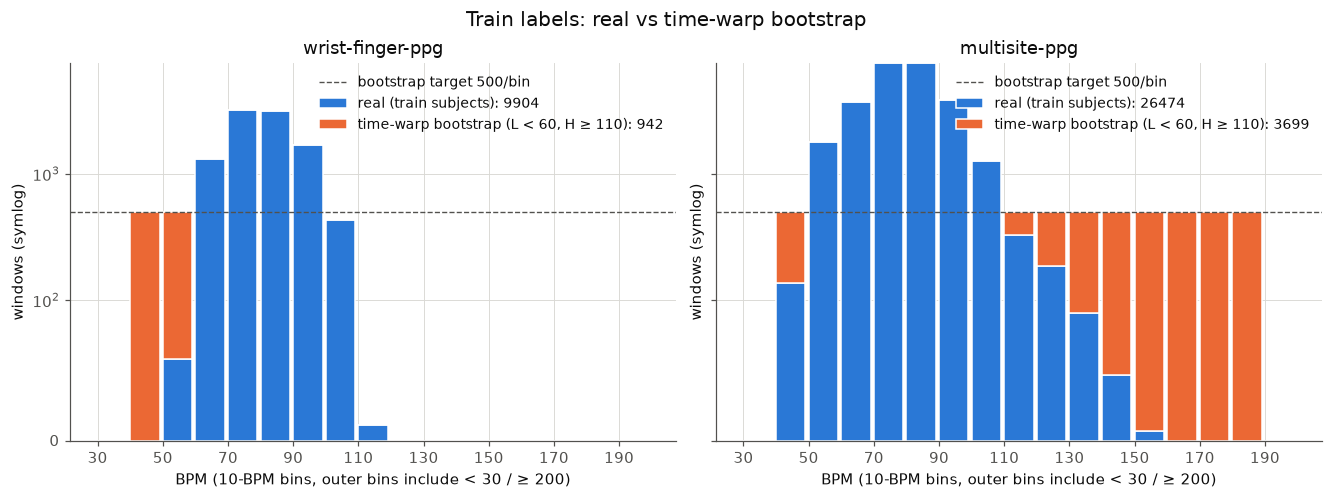

In [25]:
edges = np.arange(30, 201, 10)
fig, axes = plt.subplots(1, 2, figsize=figsize(1.7), sharey=True)
for ax, ds in zip(axes, DATASETS):
    bottom = np.zeros(len(edges) - 1)
    boot_ds = pd.concat([boot["L"], boot["H"]])
    series = [("real", real[(real.sub_dataset == ds) & (real.split == "train")].bpm, "real (train subjects)"),
              ("boot", boot_ds[boot_ds.sub_dataset == ds].bpm, "time-warp bootstrap (L < 60, H ≥ 110)")]
    for key, vals, lab in series:
        cnt, _ = np.histogram(np.clip(vals, edges[0], edges[-1] - 1e-3), edges)
        if cnt.any():
            ax.bar(edges[:-1], cnt, width=9, bottom=bottom, align="edge", color=COLORS[key],
                   edgecolor=COLORS["surface"], linewidth=1, label=f"{lab}: {cnt.sum()}")
        bottom += cnt
    ax.axhline(TARGET_PER_BIN, color=COLORS["muted"], ls="--", lw=STYLE["lw_thin"],
               label=f"bootstrap target {TARGET_PER_BIN}/bin")
    ax.set_yscale("symlog", linthresh=100)
    ax.set(title=ds, xlabel="BPM (10-BPM bins, outer bins include < 30 / ≥ 200)", ylabel="windows (symlog)")
    ax.set_xticks(edges[::2])
    ax.legend(loc="upper right")
fig.suptitle("Train labels: real vs time-warp bootstrap");

**What it shows:** training labels per 10-BPM bin, real windows (blue) and stacked bootstrap windows (orange; `L` and `H` never share a bin). Real labels cluster at 60-100 BPM; the bootstrap tops the sparse tails up toward 500 windows per bin (`L` 40-60 for both sub-datasets, `H` 110-190 for multisite only, see `build_bootstrap.py`). Bins that stay below the line ran out of usable source windows. y axis is symlog so the tails stay visible next to the dense center.

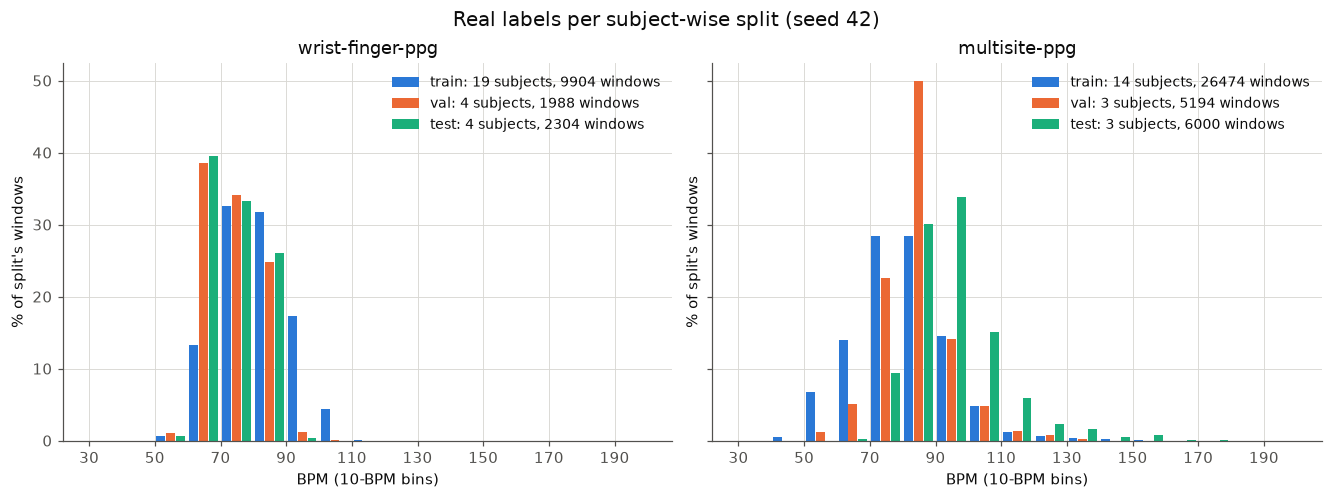

In [26]:
fig, axes = plt.subplots(1, 2, figsize=figsize(1.7), sharey=True)
w = 3
for ax, ds in zip(axes, DATASETS):
    for i, name in enumerate(["train", "val", "test"]):
        vals = real[(real.sub_dataset == ds) & (real.split == name)].bpm
        cnt, _ = np.histogram(np.clip(vals, edges[0], edges[-1] - 1e-3), edges)
        n_subj = len(split[name] & set(real[real.sub_dataset == ds].subject))
        ax.bar(edges[:-1] + 0.5 + i * w, 100 * cnt / max(cnt.sum(), 1), width=w - 0.3, align="edge",
               color=COLORS[name], label=f"{name}: {n_subj} subjects, {cnt.sum()} windows")
    ax.set(title=ds, xlabel="BPM (10-BPM bins)", ylabel="% of split's windows")
    ax.set_xticks(edges[::2])
    ax.legend(loc="upper right")
fig.suptitle("Real labels per subject-wise split (seed 42)");

**What it shows:** the label distribution of each split, normalised to percent so splits of different size compare. With only 3-4 val/test subjects per sub-dataset, the splits can differ noticeably; a test set without high-BPM windows cannot measure high-BPM accuracy.

## Notes

- Gate stats and gate examples use all wrist-finger files but only a sample of multisite files (2 per subject, 1800-20000 s) to keep the notebook fast. The BPM distribution plots read the full window caches.
- The per-gate split (`gate_masks`) mirrors `ground_truth.py` and `cache.read_ppg_and_hr`; the assert in the helper cell fails if the library changes and the two drift apart.